# Kompleksowe testowanie wytrenowanych modeli

Notebook porównuje wszystkie wytrenowane modele na dedykowanych zbiorach
testowych. Modele nie są tutaj ponownie uczone.

Wpływ hiperparametrów oraz macierze pomyłek są prezentowane w notebookach
poszczególnych algorytmów i nie są tutaj powielane.

### Mapa wyników

- **Sekcja 7** — wpływ liczby próbek testowych na miary jakości.
- **Sekcje 8 i 11** — zagregowane miary jakości i ranking modeli.
- **Sekcje 9 i 10** — liczba, udział i przykłady błędnych klasyfikacji.
- **Sekcja 12** — statystyki końcowej fazy testowej.
- **Sekcja 14** — końcowe porównanie algorytmów przeznaczone do pracy.

Notebook wyświetla tylko reprezentatywną część szczegółowych wykresów.
Komplet polskich i angielskich grafik jest zapisywany w katalogu
`results/<zbiór>/phase_testing/plots`.


## 1. Import bibliotek i konfiguracja


In [15]:
from pathlib import Path
import os
import sys
import importlib

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings
warnings.filterwarnings('ignore')

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from utils.feature_names import get_readable_name
from utils.split_dataset_loader import feature_columns
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    MODEL_COLORS,
    dataset_display_name,
    save_dataset_figure,
)

MODELS_DIR = backend_root / 'models'
TEST_DATA_DIR = backend_root / 'data' / 'test'
RESULTS_DIR = backend_root.parent / 'results' / 'original' / 'phase_testing'
PLOTS_DIR = RESULTS_DIR / 'plots'

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

for i in range(1, 6):
    (RESULTS_DIR / f'phase_{i}').mkdir(parents=True, exist_ok=True)
    (PLOTS_DIR / f'phase_{i}').mkdir(parents=True, exist_ok=True)

(PLOTS_DIR / 'summary').mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / 'summary').mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16

np.random.seed(42)

print('✅ Biblioteki zaimportowane pomyślnie!')
print(f'\n📁 Struktura katalogów:')
print(f'  • Wyniki: {RESULTS_DIR}/')
print(f'  • Wykresy: {PLOTS_DIR}/')
print(f'  • Utworzono podfoldery dla 5 faz oraz folder summary')

✅ Biblioteki zaimportowane pomyślnie!

📁 Struktura katalogów:
  • Wyniki: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/phase_testing/
  • Wykresy: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/phase_testing/plots/
  • Utworzono podfoldery dla 5 faz oraz folder summary


## 2. Wczytanie zbiorów testowych


In [16]:
test_full = pd.read_csv(TEST_DATA_DIR / 'test_dataset_full.csv')
test_optimized = pd.read_csv(TEST_DATA_DIR / 'test_dataset_optimized.csv')

test_datasets = {
    'full': test_full,
    'optimized': test_optimized
}
DATASET_FEATURE_COUNTS = {
    name: len(feature_columns(frame)) for name, frame in test_datasets.items()
}

print('='*80)
print('WCZYTANE ZBIORY TESTOWE')
print('='*80)
for name, df in test_datasets.items():
    print(f'\n{name.upper()}:')
    print(f'  Rozmiar: {df.shape}')
    print(f'  Liczba cech: {len(feature_columns(df))}')
    print(f'  Phishing: {(df.phishing==1).sum()} ({(df.phishing==1).sum()/len(df)*100:.1f}%)')
    print(f'  Legalny URL: {(df.phishing==0).sum()} ({(df.phishing==0).sum()/len(df)*100:.1f}%)')

WCZYTANE ZBIORY TESTOWE

FULL:
  Rozmiar: (40000, 112)
  Liczba cech: 111
  Phishing: 20000 (50.0%)
  Legalny URL: 20000 (50.0%)

OPTIMIZED:
  Rozmiar: (40000, 75)
  Liczba cech: 74
  Phishing: 20000 (50.0%)
  Legalny URL: 20000 (50.0%)


## 3. Definicja struktury modeli i ładowanie


In [17]:
model_configs = [
    {
        'name': 'Regresja Logistyczna',
        'dir': 'logistic_regression',
        'model_pattern': 'logistic_regression_{}.pkl',
        'scaler_pattern': 'logistic_regression_scaler_{}.pkl',
        'has_scaler': True,
        'is_dict': False
    },
    {
        'name': 'Random Forest',
        'dir': 'random_forest',
        'model_pattern': 'random_forest_{}.pkl',
        'scaler_pattern': None,
        'has_scaler': False,
        'is_dict': True
    },
    {
        'name': 'XGBoost',
        'dir': 'xgboost',
        'model_pattern': 'xgboost_model_{}.pkl',
        'scaler_pattern': None,
        'has_scaler': False,
        'is_dict': True
    },
    {
        'name': 'SVM',
        'dir': 'svm',
        'model_pattern': 'svm_model_{}.pkl',
        'scaler_pattern': None,
        'has_scaler': False,
        'is_dict': True
    },
    {
        'name': 'MLP',
        'dir': 'mlp',
        'model_pattern': 'mlp_model_{}.pkl',
        'scaler_pattern': None,
        'has_scaler': False,
        'is_dict': True
    }
]

loaded_models = {}

print('='*80)
print('ŁADOWANIE MODELI')
print('='*80)

for config in model_configs:
    model_name = config['name']
    model_dir = MODELS_DIR / config['dir']

    loaded_models[model_name] = {}

    for dataset_type in ['full', 'optimized']:
        model_path = model_dir / config['model_pattern'].format(dataset_type)

        if model_path.exists():
            with open(model_path, 'rb') as f:
                loaded_data = pickle.load(f)

            if config['is_dict']:
                model = loaded_data['model']
                scaler = loaded_data.get('scaler', None)
            else:
                model = loaded_data
                scaler = None

                if config['has_scaler']:
                    scaler_path = model_dir / config['scaler_pattern'].format(dataset_type)
                    if scaler_path.exists():
                        with open(scaler_path, 'rb') as f:
                            scaler = pickle.load(f)

            loaded_models[model_name][dataset_type] = {
                'model': model,
                'scaler': scaler
            }
            print(f'✅ {model_name} ({dataset_type}): załadowano')
        else:
            print(f'❌ {model_name} ({dataset_type}): brak pliku {model_path.name}')

print(f'\n✅ Załadowano {sum(len(v) for v in loaded_models.values())} modeli')


ŁADOWANIE MODELI
✅ Regresja Logistyczna (full): załadowano
✅ Regresja Logistyczna (optimized): załadowano
✅ Random Forest (full): załadowano
✅ Random Forest (optimized): załadowano
✅ XGBoost (full): załadowano
✅ XGBoost (optimized): załadowano
✅ SVM (full): załadowano
✅ SVM (optimized): załadowano
✅ MLP (full): załadowano
✅ MLP (optimized): załadowano

✅ Załadowano 10 modeli


## 4. Funkcje pomocnicze


In [18]:
def prepare_test_data(df):
    columns = feature_columns(df)
    X = df[columns]
    y = df['phishing']
    return X, y

def predict_with_model(model, scaler, X):
    if scaler is not None:
        X_scaled = scaler.transform(X)
    else:
        X_scaled = X.values

    predictions = model.predict(X_scaled)

    if hasattr(model, 'predict_proba'):
        probabilities = model.predict_proba(X_scaled)[:, 1]
    elif hasattr(model, 'decision_function'):
        probabilities = model.decision_function(X_scaled)
        probabilities = 1 / (1 + np.exp(-probabilities))
    else:
        probabilities = predictions.flatten()

    if len(predictions.shape) > 1:
        predictions = (predictions > 0.5).astype(int).flatten()

    return predictions, probabilities

def calculate_metrics(y_true, y_pred, y_proba):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_proba),
        'confusion_matrix': confusion_matrix(y_true, y_pred)
    }

def analyze_misclassifications(X, y_true, y_pred, y_proba, indices):
    misclassified = []

    for idx in indices:
        if y_true.iloc[idx] != y_pred[idx]:
            misclassified.append({
                'index': idx,
                'true_label': y_true.iloc[idx],
                'predicted_label': y_pred[idx],
                'probability': y_proba[idx],
                'features': X.iloc[idx].to_dict()
            })

    return misclassified

print('✅ Funkcje pomocnicze zdefiniowane')


✅ Funkcje pomocnicze zdefiniowane


## 5. Testowanie modeli w 5 fazach z różnymi rozkładami danych


In [19]:
def create_phase_dataset(df, n_samples, phishing_ratio):
    phishing_count = int(n_samples * phishing_ratio)
    legitimate_count = n_samples - phishing_count

    phishing_available = (df['phishing'] == 1).sum()
    legitimate_available = (df['phishing'] == 0).sum()

    if phishing_count > phishing_available:
        phishing_samples = df[df['phishing'] == 1].sample(n=phishing_available, random_state=42, replace=False)
        phishing_samples = pd.concat([phishing_samples] * (phishing_count // phishing_available + 1), ignore_index=True)
        phishing_samples = phishing_samples.sample(n=phishing_count, random_state=42, replace=False)
    else:
        phishing_samples = df[df['phishing'] == 1].sample(n=phishing_count, random_state=42, replace=False)

    if legitimate_count > legitimate_available:
        legitimate_samples = df[df['phishing'] == 0].sample(n=legitimate_available, random_state=42, replace=False)
        legitimate_samples = pd.concat([legitimate_samples] * (legitimate_count // legitimate_available + 1), ignore_index=True)
        legitimate_samples = legitimate_samples.sample(n=legitimate_count, random_state=42, replace=False)
    else:
        legitimate_samples = df[df['phishing'] == 0].sample(n=legitimate_count, random_state=42, replace=False)

    phase_df = pd.concat([phishing_samples, legitimate_samples], ignore_index=True)
    phase_df = phase_df.sample(frac=1, random_state=42).reset_index(drop=True)

    return phase_df

test_phases = [
    {
        'name': 'Faza 1: Mini Test',
        'size': 2,
        'distributions': [
            {'phishing': 0.5, 'label': '50% phishing, 50% bezpieczne'}
        ]
    },
    {
        'name': 'Faza 2: 1,000 próbek',
        'size': 1000,
        'distributions': [
            {'phishing': 0.7, 'label': '70% phishing, 30% bezpieczne'},
            {'phishing': 0.3, 'label': '30% phishing, 70% bezpieczne'},
            {'phishing': 0.5, 'label': '50% phishing, 50% bezpieczne'}
        ]
    },
    {
        'name': 'Faza 3: 5,000 próbek',
        'size': 5000,
        'distributions': [
            {'phishing': 0.7, 'label': '70% phishing, 30% bezpieczne'},
            {'phishing': 0.3, 'label': '30% phishing, 70% bezpieczne'},
            {'phishing': 0.5, 'label': '50% phishing, 50% bezpieczne'}
        ]
    },
    {
        'name': 'Faza 4: 10,000 próbek',
        'size': 10000,
        'distributions': [
            {'phishing': 0.7, 'label': '70% phishing, 30% bezpieczne'},
            {'phishing': 0.3, 'label': '30% phishing, 70% bezpieczne'},
            {'phishing': 0.5, 'label': '50% phishing, 50% bezpieczne'}
        ]
    },
    {
        'name': 'Faza 5: 20,000 próbek',
        'size': 20000,
        'distributions': [
            {'phishing': 0.7, 'label': '70% phishing, 30% bezpieczne'},
            {'phishing': 0.3, 'label': '30% phishing, 70% bezpieczne'},
            {'phishing': 0.5, 'label': '50% phishing, 50% bezpieczne'}
        ]
    }
]

phase_results = {}

print('='*100)
print('TESTOWANIE FAZOWE MODELI')
print('='*100)

for phase_idx, phase in enumerate(test_phases, 1):
    print(f'\n{"="*100}')
    print(f'{phase["name"].upper()}')
    print(f'{"="*100}')

    phase_results[phase['name']] = {}

    for model_name, datasets in loaded_models.items():
        phase_results[phase['name']][model_name] = {}

        for dataset_type, model_data in datasets.items():
            phase_results[phase['name']][model_name][dataset_type] = {}

            test_df = test_datasets[dataset_type]
            model = model_data['model']
            scaler = model_data['scaler']

            print(f'\n{model_name} - {dataset_type.upper()}')
            print('-'*100)

            for dist in phase['distributions']:
                dist_df = create_phase_dataset(test_df, phase['size'], dist['phishing'])
                X_test, y_test = prepare_test_data(dist_df)

                predictions, probabilities = predict_with_model(model, scaler, X_test)
                metrics = calculate_metrics(y_test, predictions, probabilities)
                misclassified = analyze_misclassifications(
                    X_test, y_test, predictions, probabilities, range(len(y_test))
                )

                phase_results[phase['name']][model_name][dataset_type][dist['label']] = {
                    'metrics': metrics,
                    'misclassified': misclassified,
                    'distribution': dist
                }

                print(f"  {dist['label']}:")
                print(f"    Dokładność: {metrics['accuracy']:.4f} | Precyzja: {metrics['precision']:.4f} | "
                      f"Czułość: {metrics['recall']:.4f} | F1: {metrics['f1']:.4f} | "
                      f"ROC-AUC: {metrics['roc_auc']:.4f} | Błędy: {len(misclassified)}/{len(y_test)}")

print(f'\n{"="*100}')
print('✅ Testowanie fazowe zakończone')
print(f'{"="*100}')

TESTOWANIE FAZOWE MODELI

FAZA 1: MINI TEST

Regresja Logistyczna - FULL
----------------------------------------------------------------------------------------------------
  50% phishing, 50% bezpieczne:
    Dokładność: 1.0000 | Precyzja: 1.0000 | Czułość: 1.0000 | F1: 1.0000 | ROC-AUC: 1.0000 | Błędy: 0/2

Regresja Logistyczna - OPTIMIZED
----------------------------------------------------------------------------------------------------
  50% phishing, 50% bezpieczne:
    Dokładność: 1.0000 | Precyzja: 1.0000 | Czułość: 1.0000 | F1: 1.0000 | ROC-AUC: 1.0000 | Błędy: 0/2

Random Forest - FULL
----------------------------------------------------------------------------------------------------
  50% phishing, 50% bezpieczne:
    Dokładność: 1.0000 | Precyzja: 1.0000 | Czułość: 1.0000 | F1: 1.0000 | ROC-AUC: 1.0000 | Błędy: 0/2

Random Forest - OPTIMIZED
----------------------------------------------------------------------------------------------------
  50% phishing, 50% bezpieczne:


## 6. Podsumowanie wyników fazowych - szczegółowe tabele


In [20]:
phase_summary_data = []

for phase_name, models in phase_results.items():
    for model_name, datasets in models.items():
        for dataset_type, distributions in datasets.items():
            for dist_label, results in distributions.items():
                metrics = results['metrics']
                phase_summary_data.append({
                    'Faza': phase_name,
                    'Model': model_name,
                    'Zbior': dataset_type,
                    'Rozklad': dist_label,
                    'Dokladnosc': metrics['accuracy'],
                    'Precyzja': metrics['precision'],
                    'Czulosc': metrics['recall'],
                    'F1': metrics['f1'],
                    'ROC-AUC': metrics['roc_auc'],
                    'Bledne': len(results['misclassified'])
                })

phase_summary_df = pd.DataFrame(phase_summary_data)

print('='*120)
print('SZCZEGOLOWE PODSUMOWANIE WYNIKOW FAZOWYCH')
print('='*120)

phase_mapping = {
    'Faza 1: Mini Test': 1,
    'Faza 2: 1,000 probek': 2,
    'Faza 2: 1,000 próbek': 2,
    'Faza 3: 5,000 probek': 3,
    'Faza 3: 5,000 próbek': 3,
    'Faza 4: 10,000 probek': 4,
    'Faza 4: 10,000 próbek': 4,
    'Faza 5: 20,000 probek': 5,
    'Faza 5: 20,000 próbek': 5
}

for dataset_type in ['full', 'optimized']:
    print(f'\n{"#"*120}')
    print(f'WYNIKI DLA ZBIORU: {dataset_type}')
    print(f'{"#"*120}')

    dataset_data = phase_summary_df[phase_summary_df['Zbior'] == dataset_type]

    for phase_name in dataset_data['Faza'].unique():
        phase_data = dataset_data[dataset_data['Faza'] == phase_name]
        phase_data_sorted = phase_data.sort_values(['ROC-AUC', 'F1'], ascending=False)

        print(f'\n{phase_name} - {dataset_type}')
        print('-'*100)
        display_cols = ['Model', 'Rozklad', 'Dokladnosc', 'Precyzja', 'Czulosc', 'F1', 'ROC-AUC', 'Bledne']
        print(phase_data_sorted[display_cols].to_string(index=False))

        phase_num = phase_mapping[phase_name]
        dataset_suffix = 'full' if 'Pelny' in dataset_type else 'optimized'
        csv_path = RESULTS_DIR / f'phase_{phase_num}' / f'phase_{phase_num}_{dataset_suffix}_results.csv'
        phase_data_sorted.to_csv(csv_path, index=False)
        print(f'Zapisano do: {csv_path}')

csv_all_path = RESULTS_DIR / 'summary' / 'all_phases_results.csv'
phase_summary_df.to_csv(csv_all_path, index=False)

print(f'\n{"="*120}')
print(f'Zapisano wszystkie wyniki do: {csv_all_path}')
print(f'Zapisano {len(phase_summary_df)} wynikow w {len(phase_mapping)*2} plikach fazowych')
print(f'{"="*120}')


print('\n' + '='*120)
print('PODSUMOWANIE WEDLUG MODELI - SREDNIE METRYKI')
print('='*120)

print('\n' + '#'*80)
print(f'PELNY ZBIOR DANYCH ({DATASET_FEATURE_COUNTS["full"]} cech)')
print('#'*80)
full_dataset_summary = phase_summary_df[phase_summary_df['Zbior'] == 'full'].groupby('Model').agg({
    'Dokladnosc': ['mean', 'std'],
    'Precyzja': ['mean', 'std'],
    'Czulosc': ['mean', 'std'],
    'F1': ['mean', 'std'],
    'ROC-AUC': ['mean', 'std'],
    'Bledne': 'sum'
}).round(4)

full_dataset_flat = pd.DataFrame()
for model in full_dataset_summary.index:
    full_dataset_flat.loc[model, 'Dokladnosc (sr.)'] = full_dataset_summary.loc[model, ('Dokladnosc', 'mean')]
    full_dataset_flat.loc[model, 'Dokladnosc (std)'] = full_dataset_summary.loc[model, ('Dokladnosc', 'std')]
    full_dataset_flat.loc[model, 'Precyzja (sr.)'] = full_dataset_summary.loc[model, ('Precyzja', 'mean')]
    full_dataset_flat.loc[model, 'Precyzja (std)'] = full_dataset_summary.loc[model, ('Precyzja', 'std')]
    full_dataset_flat.loc[model, 'Czulosc (sr.)'] = full_dataset_summary.loc[model, ('Czulosc', 'mean')]
    full_dataset_flat.loc[model, 'Czulosc (std)'] = full_dataset_summary.loc[model, ('Czulosc', 'std')]
    full_dataset_flat.loc[model, 'F1 (sr.)'] = full_dataset_summary.loc[model, ('F1', 'mean')]
    full_dataset_flat.loc[model, 'F1 (std)'] = full_dataset_summary.loc[model, ('F1', 'std')]
    full_dataset_flat.loc[model, 'ROC-AUC (sr.)'] = full_dataset_summary.loc[model, ('ROC-AUC', 'mean')]
    full_dataset_flat.loc[model, 'ROC-AUC (std)'] = full_dataset_summary.loc[model, ('ROC-AUC', 'std')]
    full_dataset_flat.loc[model, 'Suma bledow'] = full_dataset_summary.loc[model, ('Bledne', 'sum')]

full_dataset_flat = full_dataset_flat.sort_values('ROC-AUC (sr.)', ascending=False)
print(full_dataset_flat.round(4))

print('\n' + '#'*80)
print(f'ZOPTYMALIZOWANY ZBIOR DANYCH ({DATASET_FEATURE_COUNTS["optimized"]} cech)')
print('#'*80)
opt_dataset_summary = phase_summary_df[phase_summary_df['Zbior'] == 'optimized'].groupby('Model').agg({
    'Dokladnosc': ['mean', 'std'],
    'Precyzja': ['mean', 'std'],
    'Czulosc': ['mean', 'std'],
    'F1': ['mean', 'std'],
    'ROC-AUC': ['mean', 'std'],
    'Bledne': 'sum'
}).round(4)

opt_dataset_flat = pd.DataFrame()
for model in opt_dataset_summary.index:
    opt_dataset_flat.loc[model, 'Dokladnosc (sr.)'] = opt_dataset_summary.loc[model, ('Dokladnosc', 'mean')]
    opt_dataset_flat.loc[model, 'Dokladnosc (std)'] = opt_dataset_summary.loc[model, ('Dokladnosc', 'std')]
    opt_dataset_flat.loc[model, 'Precyzja (sr.)'] = opt_dataset_summary.loc[model, ('Precyzja', 'mean')]
    opt_dataset_flat.loc[model, 'Precyzja (std)'] = opt_dataset_summary.loc[model, ('Precyzja', 'std')]
    opt_dataset_flat.loc[model, 'Czulosc (sr.)'] = opt_dataset_summary.loc[model, ('Czulosc', 'mean')]
    opt_dataset_flat.loc[model, 'Czulosc (std)'] = opt_dataset_summary.loc[model, ('Czulosc', 'std')]
    opt_dataset_flat.loc[model, 'F1 (sr.)'] = opt_dataset_summary.loc[model, ('F1', 'mean')]
    opt_dataset_flat.loc[model, 'F1 (std)'] = opt_dataset_summary.loc[model, ('F1', 'std')]
    opt_dataset_flat.loc[model, 'ROC-AUC (sr.)'] = opt_dataset_summary.loc[model, ('ROC-AUC', 'mean')]
    opt_dataset_flat.loc[model, 'ROC-AUC (std)'] = opt_dataset_summary.loc[model, ('ROC-AUC', 'std')]
    opt_dataset_flat.loc[model, 'Suma bledow'] = opt_dataset_summary.loc[model, ('Bledne', 'sum')]

opt_dataset_flat = opt_dataset_flat.sort_values('ROC-AUC (sr.)', ascending=False)
print(opt_dataset_flat.round(4))

print('\n' + '#'*80)
print('BEZPOSREDNIE POROWNANIE ZBIOROW DANYCH')
print('#'*80)
comparison_data = []
for model in full_dataset_flat.index:
    if model in opt_dataset_flat.index:
        comparison_data.append({
            'Model': model,
            'Pelny - ROC-AUC (sr.)': full_dataset_flat.loc[model, 'ROC-AUC (sr.)'],
            'Opt. - ROC-AUC (sr.)': opt_dataset_flat.loc[model, 'ROC-AUC (sr.)'],
            'Roznica ROC-AUC': opt_dataset_flat.loc[model, 'ROC-AUC (sr.)'] - full_dataset_flat.loc[model, 'ROC-AUC (sr.)'],
            'Pelny - F1 (sr.)': full_dataset_flat.loc[model, 'F1 (sr.)'],
            'Opt. - F1 (sr.)': opt_dataset_flat.loc[model, 'F1 (sr.)'],
            'Roznica F1': opt_dataset_flat.loc[model, 'F1 (sr.)'] - full_dataset_flat.loc[model, 'F1 (sr.)']
        })

comparison_df = pd.DataFrame(comparison_data).sort_values('Roznica ROC-AUC', ascending=False)
print(comparison_df.round(4))

full_summary_path = RESULTS_DIR / 'summary' / 'full_dataset_model_summary.csv'
opt_summary_path = RESULTS_DIR / 'summary' / 'optimized_dataset_model_summary.csv'
comparison_path = RESULTS_DIR / 'summary' / 'dataset_comparison.csv'

full_dataset_flat.to_csv(full_summary_path)
opt_dataset_flat.to_csv(opt_summary_path)
comparison_df.to_csv(comparison_path, index=False)

print(f'\nZapisano podsumowanie pelnego zbioru do: {full_summary_path}')
print(f'Zapisano podsumowanie zoptymalizowanego zbioru do: {opt_summary_path}')
print(f'Zapisano porownanie zbiorow do: {comparison_path}')

SZCZEGOLOWE PODSUMOWANIE WYNIKOW FAZOWYCH

########################################################################################################################
WYNIKI DLA ZBIORU: full
########################################################################################################################

Faza 1: Mini Test - full
----------------------------------------------------------------------------------------------------
               Model                      Rozklad  Dokladnosc  Precyzja  Czulosc  F1  ROC-AUC  Bledne
Regresja Logistyczna 50% phishing, 50% bezpieczne         1.0       1.0      1.0 1.0      1.0       0
       Random Forest 50% phishing, 50% bezpieczne         1.0       1.0      1.0 1.0      1.0       0
             XGBoost 50% phishing, 50% bezpieczne         1.0       1.0      1.0 1.0      1.0       0
                 SVM 50% phishing, 50% bezpieczne         1.0       1.0      1.0 1.0      1.0       0
                 MLP 50% phishing, 50% bezpieczne     

## 7. Wpływ liczby próbek testowych na miary jakości

Jeden zwarty wykres dla wariantu danych pokazuje cztery miary jakości. Linie
odpowiadają modelom, a kolejne punkty — wynikom dla rosnącej liczby próbek.
Miary jakości mają pełny, niezawężony zakres od 0 do 1, dlatego wykres nie
wyolbrzymia niewielkich różnic między modelami.


Wariant danych: Pełny zbiór | Porównanie miar jakości we wszystkich fazach


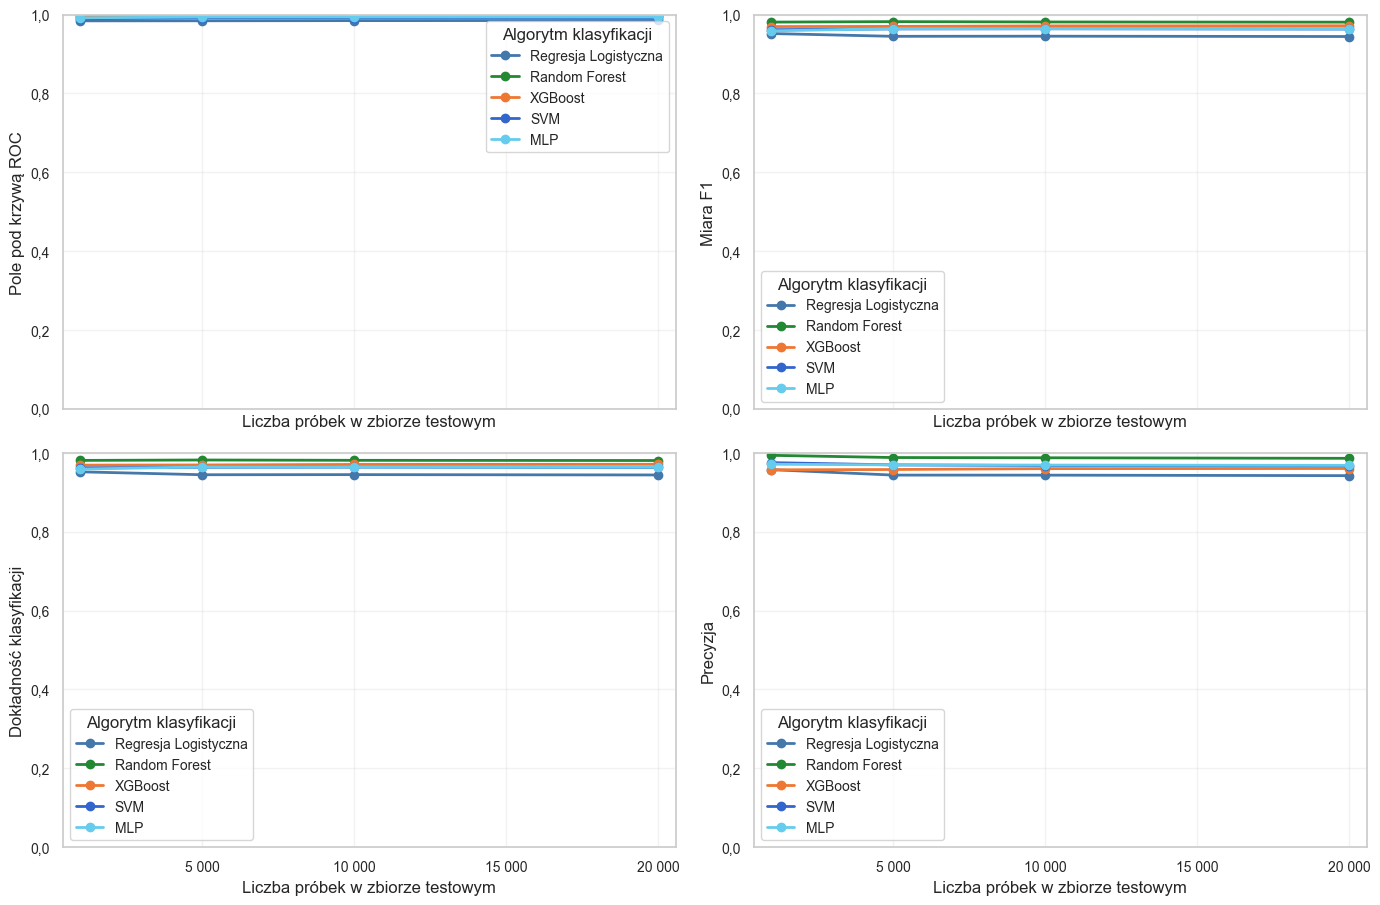

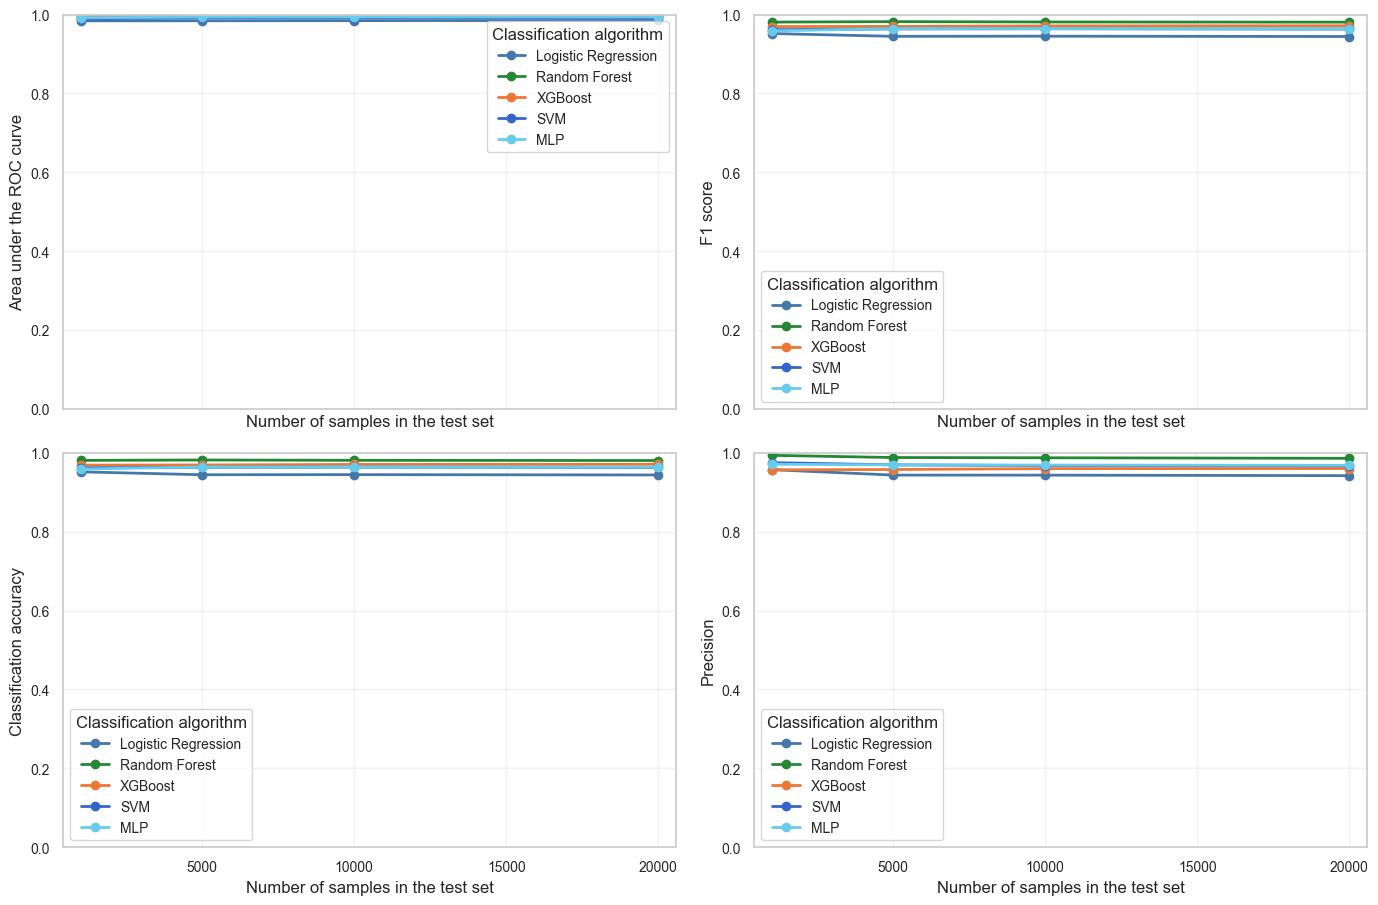

Wariant danych: Zoptymalizowany zbiór | Porównanie miar jakości we wszystkich fazach


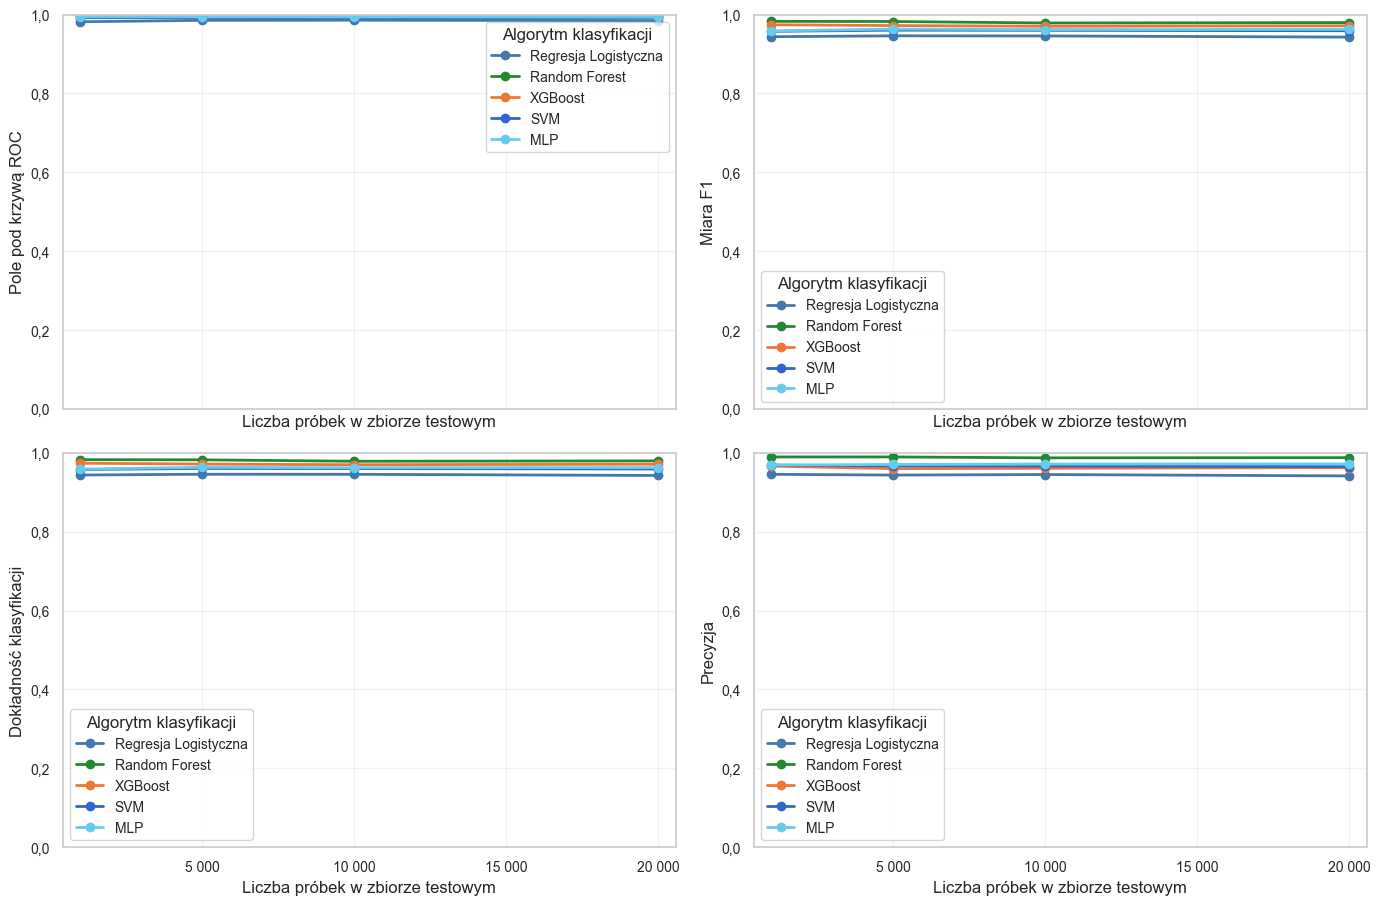

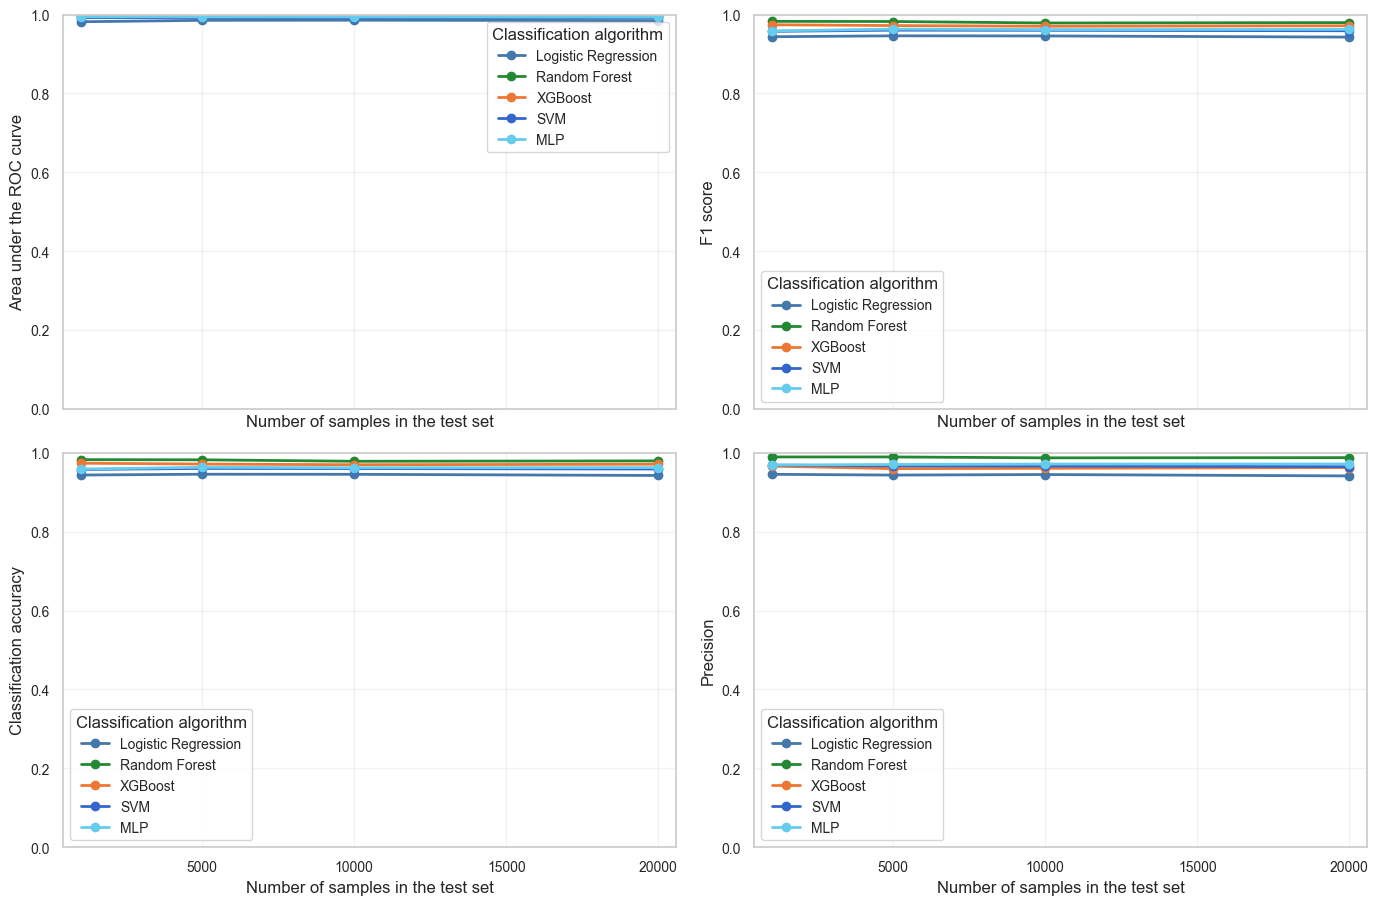

In [21]:
from utils.phase_testing_plots import (
    plot_quality_metrics_by_test_size,
    remove_legacy_phase_testing_figures,
)

remove_legacy_phase_testing_figures(PLOTS_DIR)

phase_sizes = {
    'Faza 1: Mini Test': 2,
    'Faza 2: 1,000 probek': 1000, 'Faza 2: 1,000 próbek': 1000,
    'Faza 3: 5,000 probek': 5000, 'Faza 3: 5,000 próbek': 5000,
    'Faza 4: 10,000 probek': 10000, 'Faza 4: 10,000 próbek': 10000,
    'Faza 5: 20,000 probek': 20000, 'Faza 5: 20,000 próbek': 20000,
}
phase_summary_df['Rozmiar'] = phase_summary_df['Faza'].map(phase_sizes)
metric_specs = [
    ('ROC-AUC', 'Pole pod krzywą ROC', 'roc_auc'),
    ('F1', 'Miara F1', 'f1'),
    ('Dokladnosc', 'Dokładność klasyfikacji', 'dokladnosc'),
    ('Precyzja', 'Precyzja', 'precyzja'),
]

for dataset_type in ['full', 'optimized']:
    all_series = {}
    for metric_key, metric_label, _ in metric_specs:
        metric_series = {}
        for model_name in phase_summary_df['Model'].unique():
            model_data = phase_summary_df[
                (phase_summary_df['Model'] == model_name)
                & (phase_summary_df['Zbior'] == dataset_type)
                & (phase_summary_df['Rozklad'] == '50% phishing, 50% bezpieczne')
                & (phase_summary_df['Faza'] != 'Faza 1: Mini Test')
            ].sort_values('Rozmiar')
            if not model_data.empty:
                metric_series[model_name] = (
                    model_data['Rozmiar'].tolist(),
                    model_data[metric_key].tolist(),
                )
        all_series[metric_key] = metric_series
    if not any(all_series.values()):
        continue
    figure = plot_quality_metrics_by_test_size(
        all_series, metric_specs, dataset_type,
    )
    print(
        f'Wariant danych: {dataset_display_name(dataset_type)} | '
        'Porównanie miar jakości we wszystkich fazach'
    )
    save_dataset_figure(
        figure, PLOTS_DIR / 'summary', dataset_type,
        'size_impact_quality_metrics.png',
    )
    plt.close(figure)


## 8. Średnie miary jakości modeli

Tabela agreguje wyniki faz 2–5 i wszystkich analizowanych rozkładów klas.
Służy do porównania modeli bez powielania osobnego wykresu dla każdej miary.


In [22]:
from utils.phase_testing_plots import (
    remove_obsolete_average_metric_figures,
)

avg_metrics_data = []
for phase_name, phase_data in phase_results.items():
    if phase_name == 'Faza 1: Mini Test':
        continue
    for dist_label in [
        '70% phishing, 30% bezpieczne', '30% phishing, 70% bezpieczne',
        '50% phishing, 50% bezpieczne',
    ]:
        for model_name, datasets in phase_data.items():
            for dataset_type in ['full', 'optimized']:
                if dataset_type in datasets and dist_label in datasets[dataset_type]:
                    metrics = datasets[dataset_type][dist_label]['metrics']
                    avg_metrics_data.append({
                        'model': model_name, 'dataset': dataset_type,
                        **{key: metrics[key] for key in
                           ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']},
                    })

avg_df = pd.DataFrame(avg_metrics_data)
model_averages = avg_df.groupby(['model', 'dataset']).mean(numeric_only=True).reset_index()
remove_obsolete_average_metric_figures(PLOTS_DIR)

weights = {'roc_auc': 0.3, 'f1': 0.25, 'accuracy': 0.2,
           'precision': 0.15, 'recall': 0.1}
ranking_rows = []
for _, row in model_averages.iterrows():
    ranking_rows.append({
        'Model': row['model'],
        'Zbiór': dataset_display_name(
            row['dataset'], DATASET_FEATURE_COUNTS[row['dataset']]
        ),
        'Wynik ważony': sum(row[key] * weight for key, weight in weights.items()),
        'ROC-AUC': row['roc_auc'], 'F1': row['f1'],
        'Dokładność': row['accuracy'], 'Precyzja': row['precision'],
        'Czułość': row['recall'],
    })
final_ranking = pd.DataFrame(ranking_rows).sort_values('Wynik ważony', ascending=False)
final_ranking.to_csv(
    RESULTS_DIR / 'summary' / 'average_model_performance.csv', index=False
)
print(final_ranking.round(4))


                  Model                            Zbiór  Wynik ważony  \
3         Random Forest  Zoptymalizowany zbiór (74 cech)        0.9853   
2         Random Forest           Pełny zbiór (111 cech)        0.9852   
9               XGBoost  Zoptymalizowany zbiór (74 cech)        0.9765   
8               XGBoost           Pełny zbiór (111 cech)        0.9741   
1                   MLP  Zoptymalizowany zbiór (74 cech)        0.9705   
0                   MLP           Pełny zbiór (111 cech)        0.9701   
6                   SVM           Pełny zbiór (111 cech)        0.9695   
7                   SVM  Zoptymalizowany zbiór (74 cech)        0.9673   
4  Regresja Logistyczna           Pełny zbiór (111 cech)        0.9539   
5  Regresja Logistyczna  Zoptymalizowany zbiór (74 cech)        0.9538   

   ROC-AUC      F1  Dokładność  Precyzja  Czułość  
3   0.9978  0.9790      0.9806    0.9860   0.9722  
2   0.9974  0.9790      0.9809    0.9852   0.9730  
9   0.9956  0.9680      0.972

## 9. Błędne klasyfikacje w końcowej fazie

Zestawienie dotyczy fazy 5 i zrównoważonego rozkładu klas 50/50. Pokazuje
konkretne próbki błędnie sklasyfikowane przez modele.


In [23]:
def calculate_confidence_error(_, predicted_label, probability):
    if predicted_label == 1:
        confidence = probability
    else:
        confidence = 1 - probability
    return confidence

def create_detailed_misclassification_dataframe(model_name, dataset_type, misclassified, X_test):
    if not misclassified:
        return pd.DataFrame()

    detailed_records = []

    for miss in misclassified:
        confidence = calculate_confidence_error(
            miss['true_label'],
            miss['predicted_label'],
            miss['probability']
        )

        record = {
            'Model': model_name,
            'Zbiór': dataset_display_name(dataset_type, DATASET_FEATURE_COUNTS[dataset_type]),
            'Indeks próbki': miss['index'],
            'Prawdziwa etykieta': 'Phishing' if miss['true_label'] == 1 else 'Legalny URL',
            'Przewidziana etykieta': 'Phishing' if miss['predicted_label'] == 1 else 'Legalny URL',
            'Prawdopodobieństwo': miss['probability'],
            'Pewność błędu': confidence
        }

        top_features = sorted(
            [(k, v) for k, v in miss['features'].items()],
            key=lambda x: abs(x[1]),
            reverse=True
        )[:10]

        for i, (feat_name, feat_value) in enumerate(top_features, 1):
            readable_name = get_readable_name(feat_name)
            record[f'Cecha {i}'] = readable_name
            record[f'Wartość {i}'] = feat_value

        detailed_records.append(record)

    df = pd.DataFrame(detailed_records)
    df = df.sort_values('Pewność błędu', ascending=False)
    return df

def print_top_misclassifications(df, model_name, dataset_type, top_n=5):
    print(f'\n{"="*100}')
    print(f'TOP {top_n} NAJBARDZIEJ PEWNYCH BŁĘDÓW: {model_name} - {dataset_type.upper()}')
    print(f'{"="*100}')
    print(f'Całkowita liczba błędnych klasyfikacji: {len(df)}')
    print(f'{"-"*100}\n')

    for i, row in df.head(top_n).iterrows():
        print(f'#{i+1}. Próbka indeks: {int(row["Indeks próbki"])}')
        print(f'   Prawdziwa: {row["Prawdziwa etykieta"]} → Przewidziana: {row["Przewidziana etykieta"]}')
        print(f'   Pewność błędu: {row["Pewność błędu"]:.4f} (Prawdopodobieństwo: {row["Prawdopodobieństwo"]:.4f})')
        print(f'   Top 3 cechy:')
        for j in range(1, 4):
            if f'Cecha {j}' in row:
                print(f'     • {row[f"Cecha {j}"]}: {row[f"Wartość {j}"]:.4f}')
        print()

all_misclassifications = []

print('='*100)
print('ANALIZA BŁĘDÓW - WSZYSTKIE FAZY (ROZKŁAD 50/50)')
print('='*100)

phase_mapping = {
    'Faza 1: Mini Test': 1,
    'Faza 2: 1,000 próbek': 2,
    'Faza 3: 5,000 próbek': 3,
    'Faza 4: 10,000 próbek': 4,
    'Faza 5: 20,000 próbek': 5
}

for phase_name, phase_data in phase_results.items():
    phase_num = phase_mapping[phase_name]
    phase_misclass = []

    print(f'\n{"="*100}')
    print(f'{phase_name.upper()}')
    print(f'{"="*100}')

    for model_name, datasets in phase_data.items():
        for dataset_type, distributions in datasets.items():
            dist_50_50 = distributions.get('50% phishing, 50% bezpieczne')

            if dist_50_50 and dist_50_50['misclassified']:
                test_df = test_datasets[dataset_type]
                X_test = test_df[feature_columns(test_df)]

                df_misclass = create_detailed_misclassification_dataframe(
                    model_name, dataset_type,
                    dist_50_50['misclassified'],
                    X_test
                )

                phase_misclass.append(df_misclass)
                all_misclassifications.append(df_misclass)
                print_top_misclassifications(df_misclass, model_name, dataset_type, top_n=3)

    if phase_misclass:
        combined_phase = pd.concat(phase_misclass, ignore_index=True)
        combined_phase = combined_phase.sort_values('Pewność błędu', ascending=False)

        csv_path = RESULTS_DIR / f'phase_{phase_num}' / f'phase_{phase_num}_misclassifications.csv'
        combined_phase.to_csv(csv_path, index=False)

        print(f'\n✅ Zapisano {len(combined_phase):,} błędnych klasyfikacji do: {csv_path}')

if all_misclassifications:
    combined_df = pd.concat(all_misclassifications, ignore_index=True)
    combined_df = combined_df.sort_values('Pewność błędu', ascending=False)

    csv_path = RESULTS_DIR / 'summary' / 'all_phases_misclassifications.csv'
    combined_df.to_csv(csv_path, index=False)

    print(f'\n{"="*100}')
    print(f'✅ Zapisano {len(combined_df):,} błędnych klasyfikacji (wszystkie fazy) do: {csv_path}')
    print(f'{"="*100}')

    print(f'\nPodsumowanie błędów według modelu:')
    summary = combined_df.groupby(['Model', 'Zbiór']).agg({
        'Pewność błędu': ['count', 'mean', 'max']
    }).round(4)
    print(summary)

print('\n✅ Analiza błędnych klasyfikacji zakończona')

ANALIZA BŁĘDÓW - WSZYSTKIE FAZY (ROZKŁAD 50/50)

FAZA 1: MINI TEST

TOP 3 NAJBARDZIEJ PEWNYCH BŁĘDÓW: SVM - OPTIMIZED
Całkowita liczba błędnych klasyfikacji: 1
----------------------------------------------------------------------------------------------------

#1. Próbka indeks: 1
   Prawdziwa: Phishing → Przewidziana: Legalny URL
   Pewność błędu: 0.6497 (Prawdopodobieństwo: 0.3503)
   Top 3 cechy:
     • asn_ip: 9869.0000
     • DNS: TTL hostname: 1246.0000
     • URL: Całkowita długość: 16.0000


TOP 3 NAJBARDZIEJ PEWNYCH BŁĘDÓW: MLP - OPTIMIZED
Całkowita liczba błędnych klasyfikacji: 1
----------------------------------------------------------------------------------------------------

#1. Próbka indeks: 1
   Prawdziwa: Phishing → Przewidziana: Legalny URL
   Pewność błędu: 0.5333 (Prawdopodobieństwo: 0.4667)
   Top 3 cechy:
     • asn_ip: 9869.0000
     • DNS: TTL hostname: 1246.0000
     • URL: Całkowita długość: 16.0000


✅ Zapisano 2 błędnych klasyfikacji do: /Users/maksymilia

## 10. Wpływ liczby próbek na błędy klasyfikacji

W notebooku pokazano szczegółowe wykresy dla fazy 5 i rozkładu 50/50 oraz
zbiorcze krzywe współczynnika błędu. Pozostałe warianty zapisano do plików.


Wariant danych: Pełny zbiór | Faza: 5 | Rozkład klas: 50/50 | Udział wyników klasyfikacji


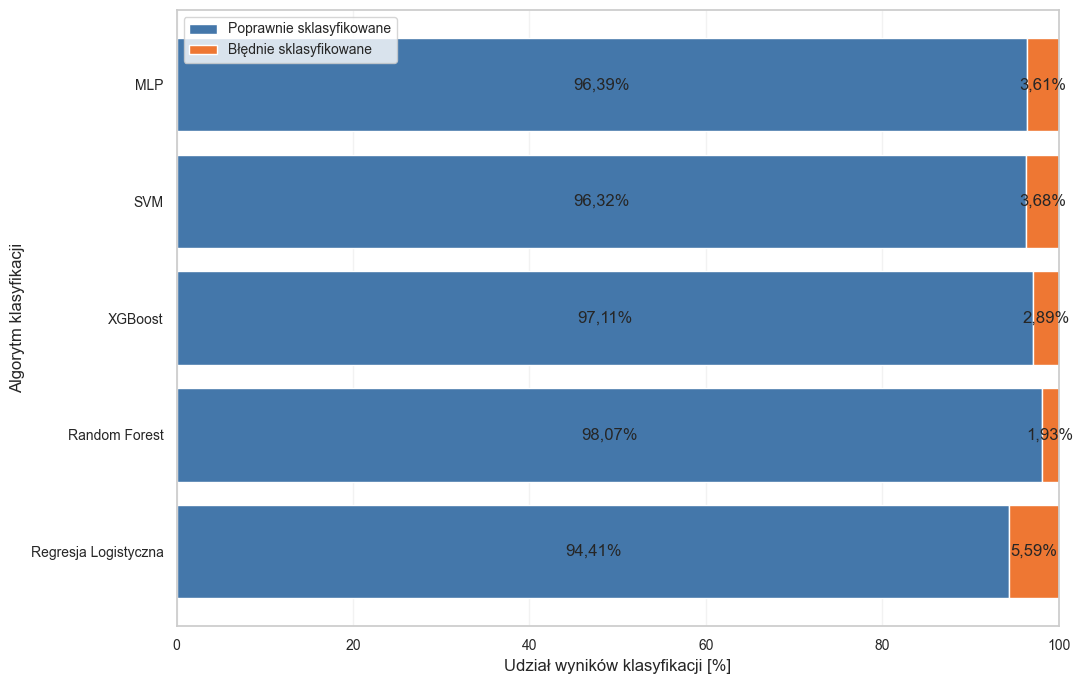

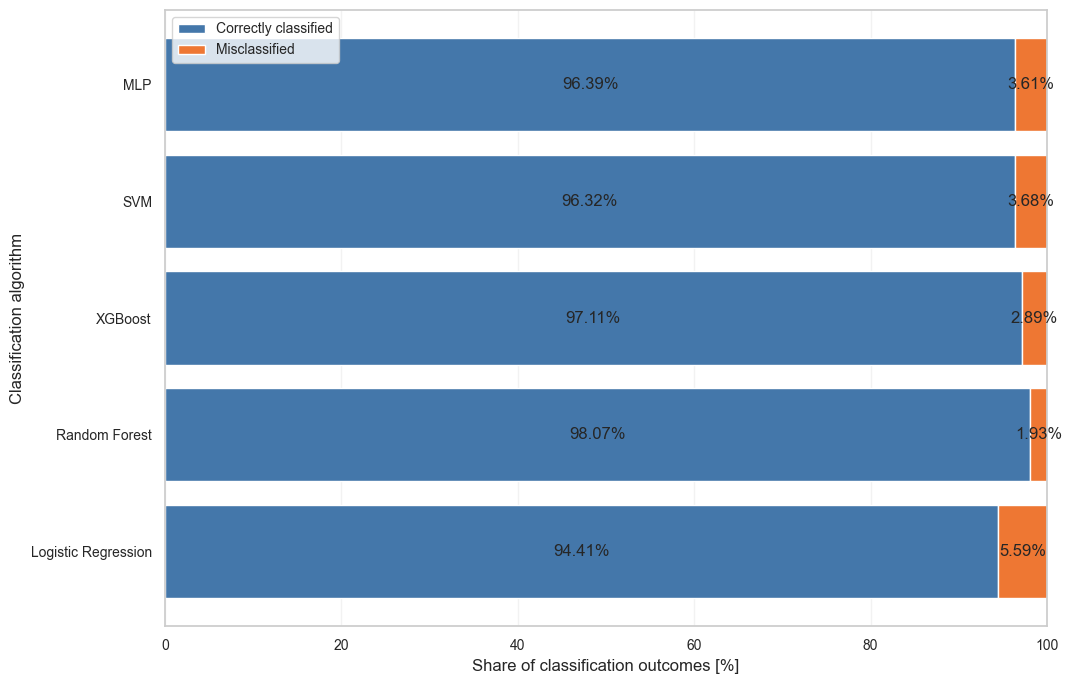

Wariant danych: Pełny zbiór | Faza: 5 | Rozkład klas: 50/50 | Liczba błędnych klasyfikacji


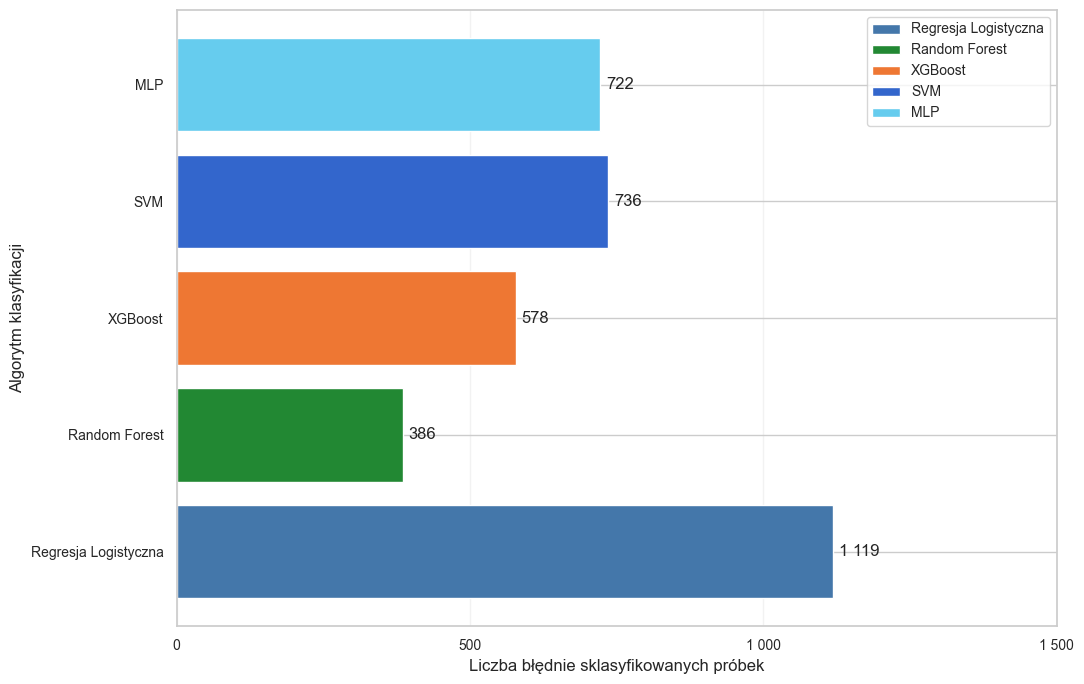

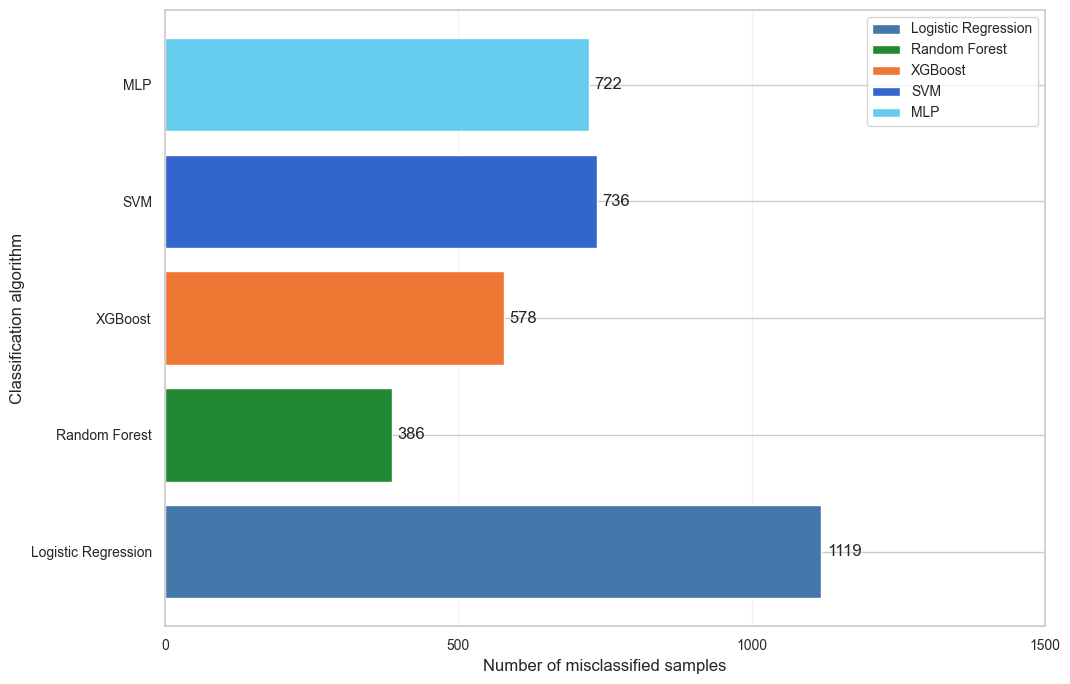

Wariant danych: Zoptymalizowany zbiór | Faza: 5 | Rozkład klas: 50/50 | Udział wyników klasyfikacji


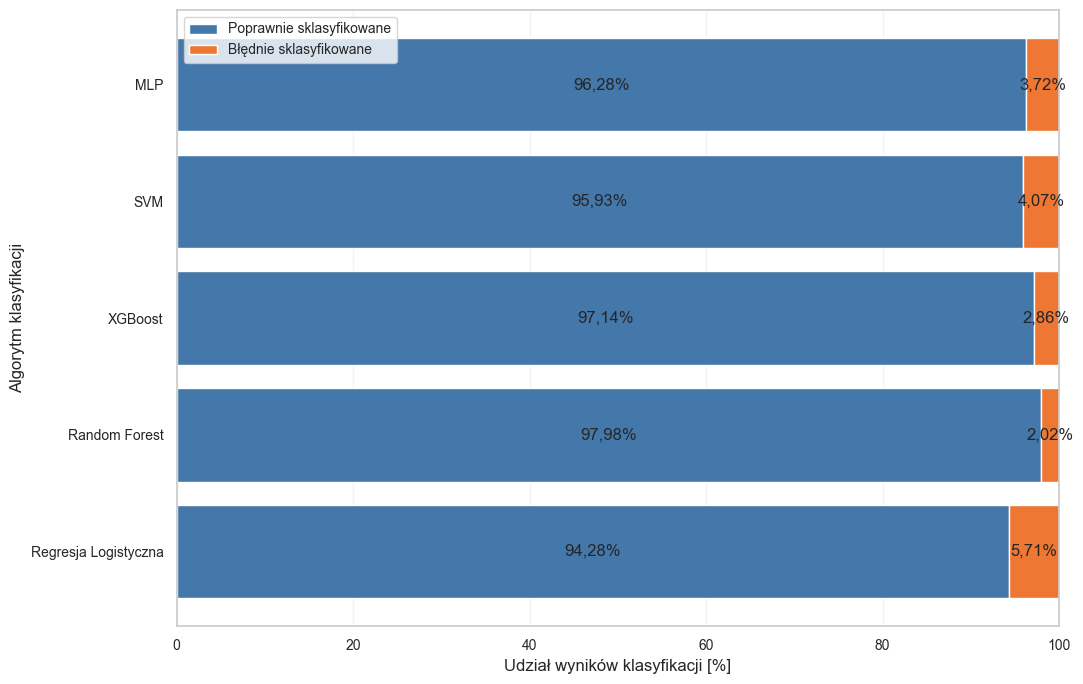

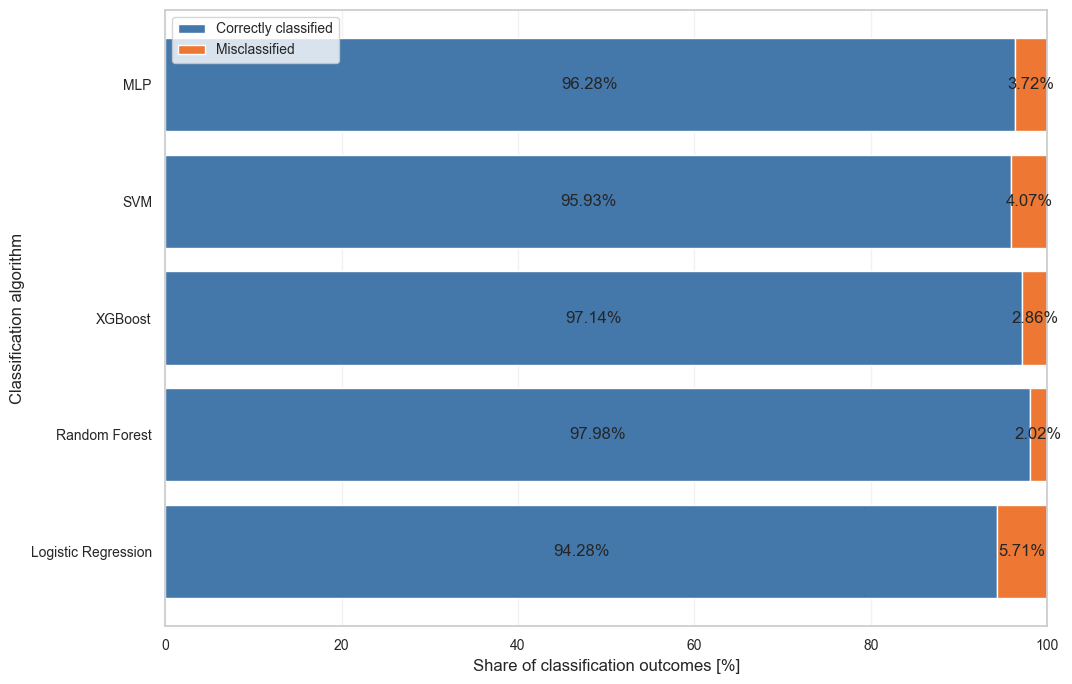

Wariant danych: Zoptymalizowany zbiór | Faza: 5 | Rozkład klas: 50/50 | Liczba błędnych klasyfikacji


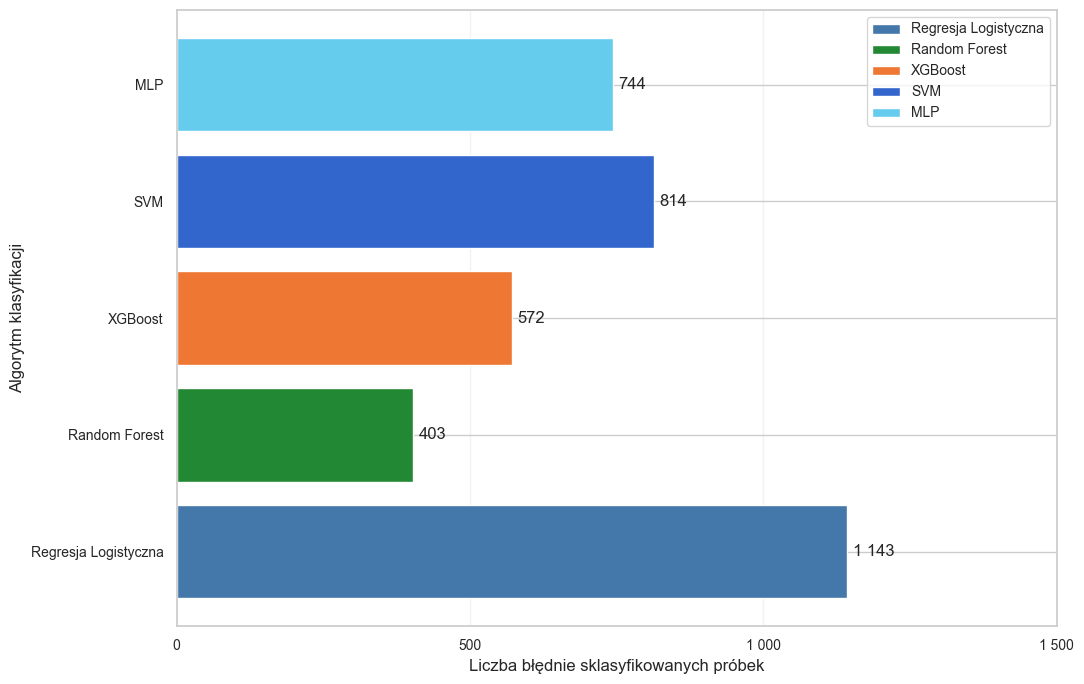

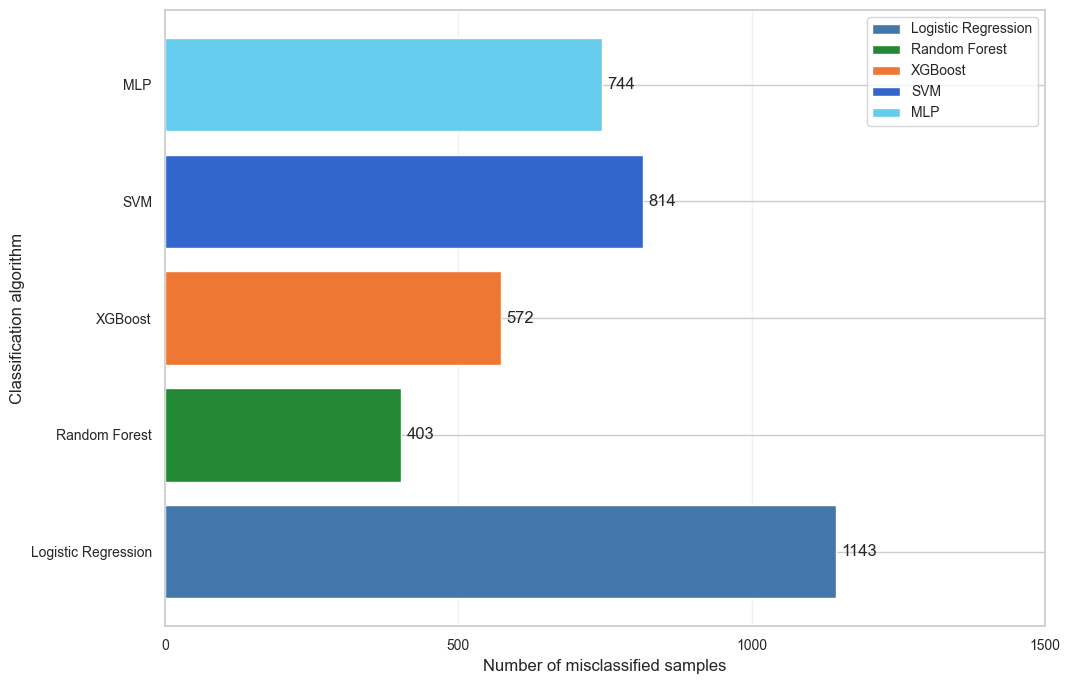

Zapisano szczegółowe wykresy błędów dla wszystkich faz i rozkładów. W notebooku pokazano fazę 5 z rozkładem klas 50/50.


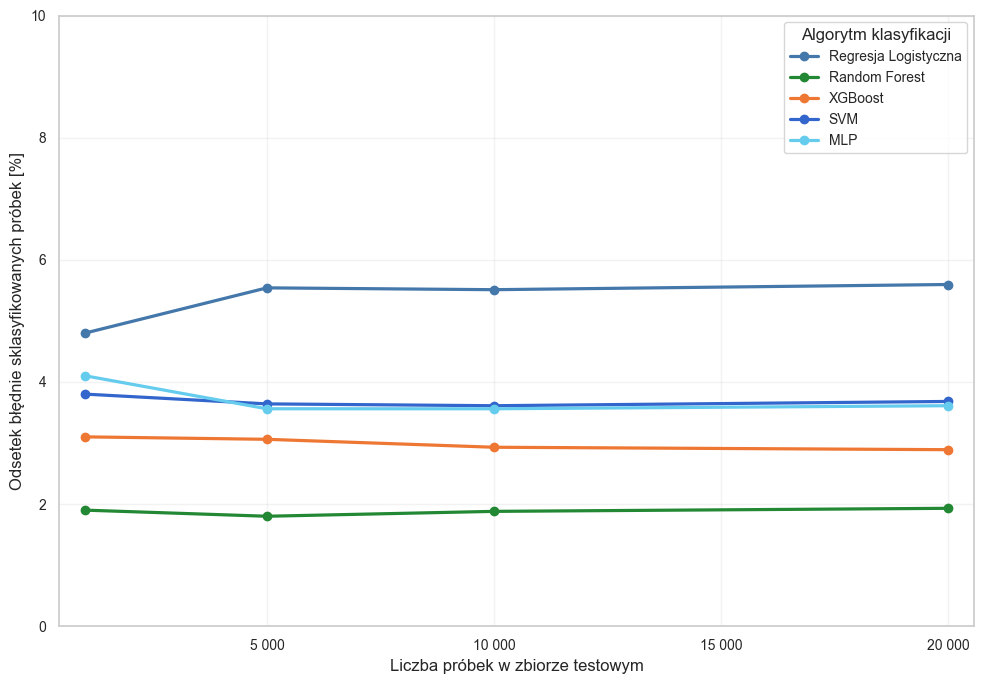

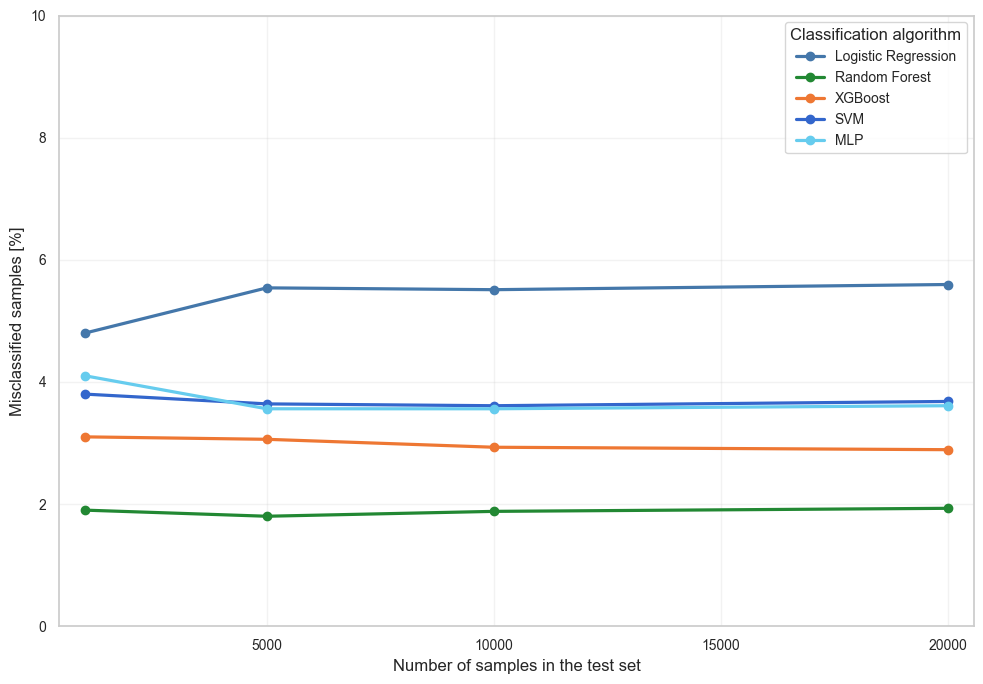

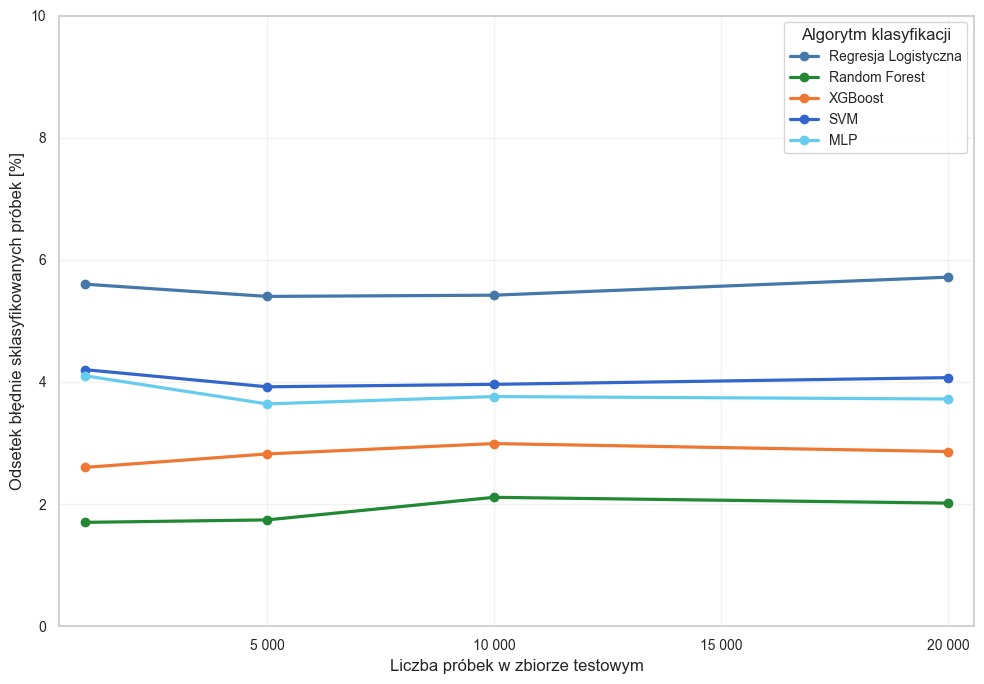

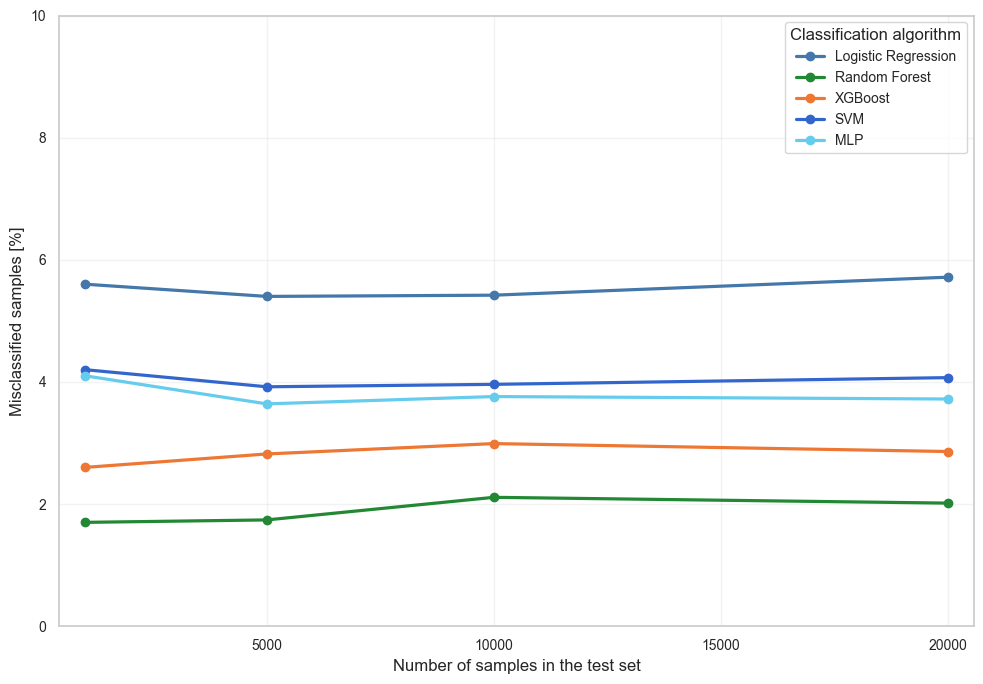

In [24]:
from utils.phase_testing_plots import (
    plot_count_ranking,
    plot_error_rate_by_test_size,
    plot_outcome_shares,
)

phase_mapping = {
    'Faza 1: Mini Test': 1, 'Faza 2: 1,000 próbek': 2,
    'Faza 3: 5,000 próbek': 3, 'Faza 4: 10,000 próbek': 4,
    'Faza 5: 20,000 próbek': 5,
}
for phase_name, phase_data in phase_results.items():
    phase_folder = PLOTS_DIR / f"phase_{phase_mapping[phase_name]}"
    phase_size = phase_summary_df[
        phase_summary_df['Faza'] == phase_name
    ]['Rozmiar'].iloc[0]
    for dist_label in [
        '70% phishing, 30% bezpieczne', '30% phishing, 70% bezpieczne',
        '50% phishing, 50% bezpieczne',
    ]:
        safe_distribution = dist_label.replace('%', 'pct').replace(',', '').replace(' ', '_')
        for dataset_type in ['full', 'optimized']:
            rows = []
            for model_name, datasets in phase_data.items():
                if dataset_type in datasets and dist_label in datasets[dataset_type]:
                    errors = len(datasets[dataset_type][dist_label]['misclassified'])
                    rows.append((model_name, phase_size - errors, errors))
            if not rows:
                continue
            models, correct, errors = map(list, zip(*rows))
            show_inline = (
                phase_mapping[phase_name] == 5
                and dist_label == '50% phishing, 50% bezpieczne'
            )
            if show_inline:
                print(
                    f'Wariant danych: {dataset_display_name(dataset_type)} | '
                    'Faza: 5 | Rozkład klas: 50/50 | '
                    'Udział wyników klasyfikacji'
                )
            figure = plot_outcome_shares(models, correct, errors)
            figure.tight_layout()
            save_dataset_figure(
                figure, phase_folder, dataset_type,
                f'classification_outcomes_{safe_distribution}.png',
                display_in_notebook=show_inline,
            )
            plt.close(figure)

            if show_inline:
                print(
                    f'Wariant danych: {dataset_display_name(dataset_type)} | '
                    'Faza: 5 | Rozkład klas: 50/50 | '
                    'Liczba błędnych klasyfikacji'
                )
            figure = plot_count_ranking(models, errors)
            figure.tight_layout()
            save_dataset_figure(
                figure, phase_folder, dataset_type,
                f'classification_error_counts_{safe_distribution}.png',
                display_in_notebook=show_inline,
            )
            plt.close(figure)

print(
    'Zapisano szczegółowe wykresy błędów dla wszystkich faz i rozkładów. '
    'W notebooku pokazano fazę 5 z rozkładem klas 50/50.'
)

comparison_data = {'full': {}, 'optimized': {}}
for phase_name, phase_data in phase_results.items():
    if phase_name == 'Faza 1: Mini Test':
        continue
    for dataset_type in comparison_data:
        comparison_data[dataset_type][phase_name] = {}
        for model_name, datasets in phase_data.items():
            balanced = '50% phishing, 50% bezpieczne'
            if dataset_type in datasets and balanced in datasets[dataset_type]:
                errors = len(datasets[dataset_type][balanced]['misclassified'])
                comparison_data[dataset_type][phase_name][model_name] = (
                    errors / phase_sizes[phase_name] * 100
                )

for dataset_type, dataset_data in comparison_data.items():
    model_series = {}
    for model_name in MODEL_COLORS:
        x_values, y_values = [], []
        for phase_name, phase in dataset_data.items():
            if model_name in phase:
                x_values.append(phase_sizes[phase_name])
                y_values.append(phase[model_name])
        if x_values:
            model_series[model_name] = (x_values, y_values)
    if not model_series:
        continue
    figure = plot_error_rate_by_test_size(model_series)
    figure.tight_layout()
    save_dataset_figure(
        figure, PLOTS_DIR / 'summary', dataset_type,
        'error_rates_by_test_size.png',
    )
    plt.close(figure)


## 11. Końcowy ranking modeli

Ranking wykorzystuje te same zagregowane wyniki co sekcja 9. Nie wykonuje
dodatkowego uczenia ani predykcji.


In [25]:
def calculate_ranking_score(metrics):
    weights = {
        'roc_auc': 0.3,
        'f1': 0.25,
        'accuracy': 0.2,
        'precision': 0.15,
        'recall': 0.1
    }
    score = sum(metrics[key] * weight for key, weight in weights.items())
    return score

ranking_data = []

for phase_name, models in phase_results.items():
    for model_name, datasets in models.items():
        for dataset_type, distributions in datasets.items():
            for dist_label, results in distributions.items():
                metrics = results['metrics']
                score = calculate_ranking_score(metrics)

                ranking_data.append({
                    'Faza': phase_name,
                    'Model': model_name,
                    'Zbiór': dataset_display_name(dataset_type, DATASET_FEATURE_COUNTS[dataset_type]),
                    'Rozkład': dist_label,
                    'Wynik rankingowy': score,
                    'ROC-AUC': metrics['roc_auc'],
                    'F1': metrics['f1'],
                    'Dokładność': metrics['accuracy'],
                    'Błędne': len(results['misclassified'])
                })

ranking_df = pd.DataFrame(ranking_data)
ranking_df = ranking_df.sort_values('Wynik rankingowy', ascending=False)

print('='*100)
print('RANKING MODELI - TOP 10 (WSZYSTKIE FAZY)')
print('='*100)
print(ranking_df.head(10).to_string(index=False))

ranking_df.to_csv(RESULTS_DIR / 'summary' / 'complete_ranking.csv', index=False)
print(f'\n✅ Ranking zapisany do: {RESULTS_DIR / "summary" / "complete_ranking.csv"}')

phase_mapping = {
    'Faza 1: Mini Test': 1,
    'Faza 2: 1,000 próbek': 2,
    'Faza 3: 5,000 próbek': 3,
    'Faza 4: 10,000 próbek': 4,
    'Faza 5: 20,000 próbek': 5
}

for phase_name in ranking_df['Faza'].unique():
    phase_num = phase_mapping[phase_name]
    phase_ranking = ranking_df[ranking_df['Faza'] == phase_name].copy()

    csv_path = RESULTS_DIR / f'phase_{phase_num}' / f'phase_{phase_num}_ranking.csv'
    phase_ranking.to_csv(csv_path, index=False)

    print(f'\n{"="*100}')
    print(f'RANKING - {phase_name.upper()}')
    print(f'{"="*100}')
    print(phase_ranking.head(10).to_string(index=False))
    print(f'\n✅ Zapisano do: {csv_path}')

print('\n' + '='*100)
print('RANKING MODELI - TOP 10 DLA KAŻDEJ FAZY (ROZKŁAD 50/50)')
print('='*100)
for phase_name in phase_summary_df['Faza'].unique():
    phase_50_50 = ranking_df[
        (ranking_df['Faza'] == phase_name) &
        (ranking_df['Rozkład'] == '50% phishing, 50% bezpieczne')
    ].sort_values('Wynik rankingowy', ascending=False)

    print(f'\n{phase_name}:')
    print(phase_50_50.head(10).to_string(index=False))
    print()

RANKING MODELI - TOP 10 (WSZYSTKIE FAZY)
                Faza                Model                           Zbiór                      Rozkład  Wynik rankingowy  ROC-AUC       F1  Dokładność  Błędne
   Faza 1: Mini Test Regresja Logistyczna          Pełny zbiór (111 cech) 50% phishing, 50% bezpieczne          1.000000 1.000000 1.000000      1.0000       0
   Faza 1: Mini Test        Random Forest          Pełny zbiór (111 cech) 50% phishing, 50% bezpieczne          1.000000 1.000000 1.000000      1.0000       0
   Faza 1: Mini Test        Random Forest Zoptymalizowany zbiór (74 cech) 50% phishing, 50% bezpieczne          1.000000 1.000000 1.000000      1.0000       0
   Faza 1: Mini Test              XGBoost          Pełny zbiór (111 cech) 50% phishing, 50% bezpieczne          1.000000 1.000000 1.000000      1.0000       0
   Faza 1: Mini Test              XGBoost Zoptymalizowany zbiór (74 cech) 50% phishing, 50% bezpieczne          1.000000 1.000000 1.000000      1.0000       0
   Fa

## 12. Statystyki fazowe — scenariusz końcowy

W notebooku pokazano szczegółowe statystyki fazy 5 osobno dla pełnego i
zoptymalizowanego wariantu danych. Statystyki faz 1–4 zapisano do plików.
Rankingi i mapy miar jakości korzystają z pełnej skali od 0 do 1.


Wariant danych: Pełny zbiór | Faza: 5 | Ranking według pola pod krzywą ROC


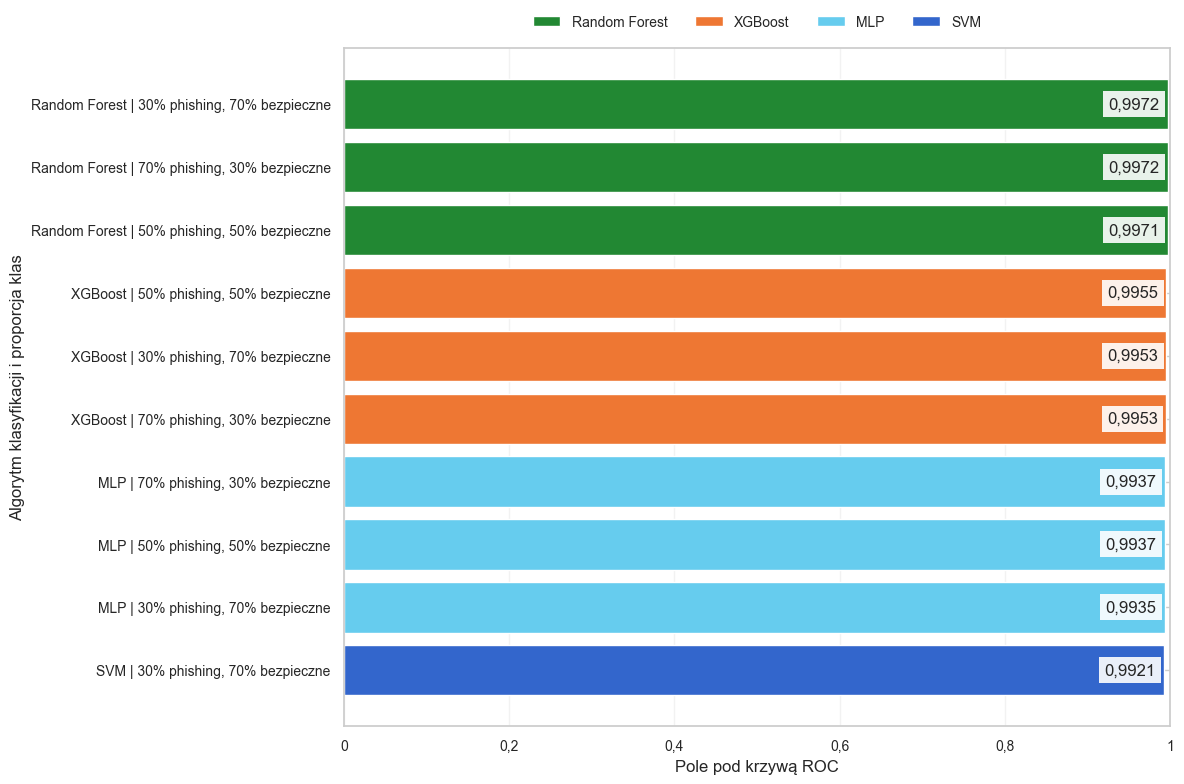

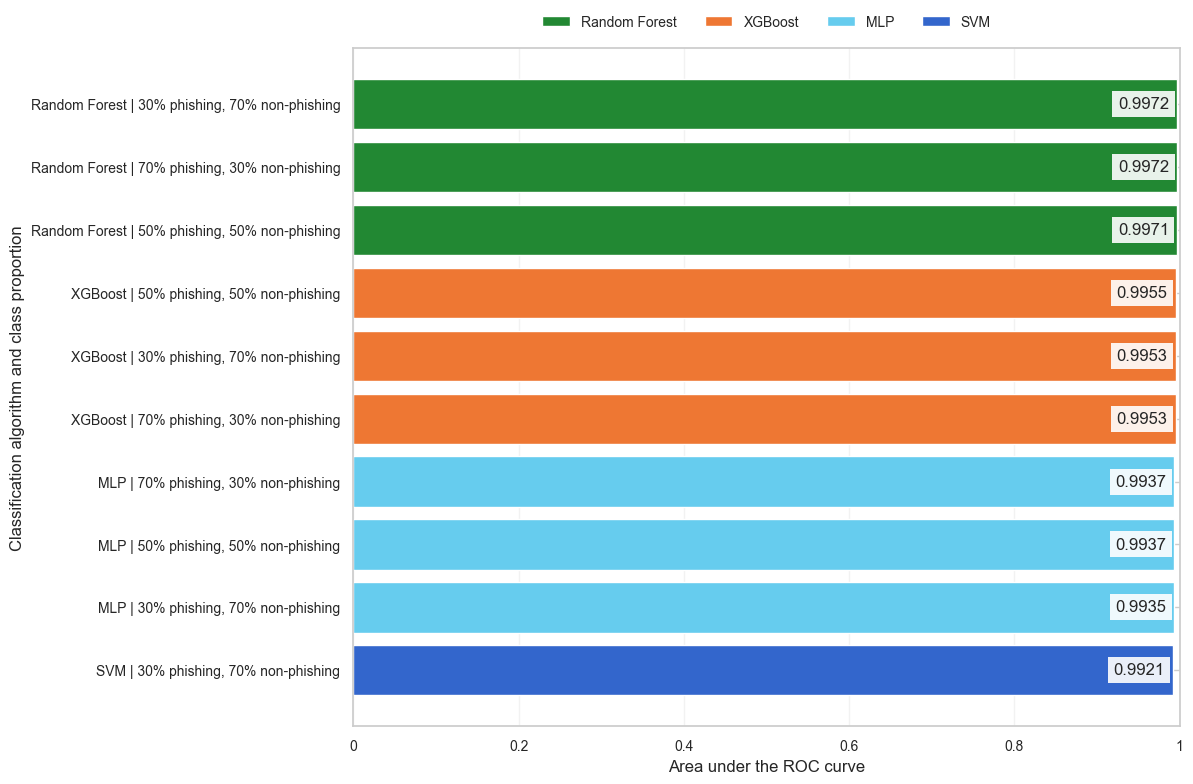

Wariant danych: Pełny zbiór | Faza: 5 | Łączna liczba błędnych klasyfikacji


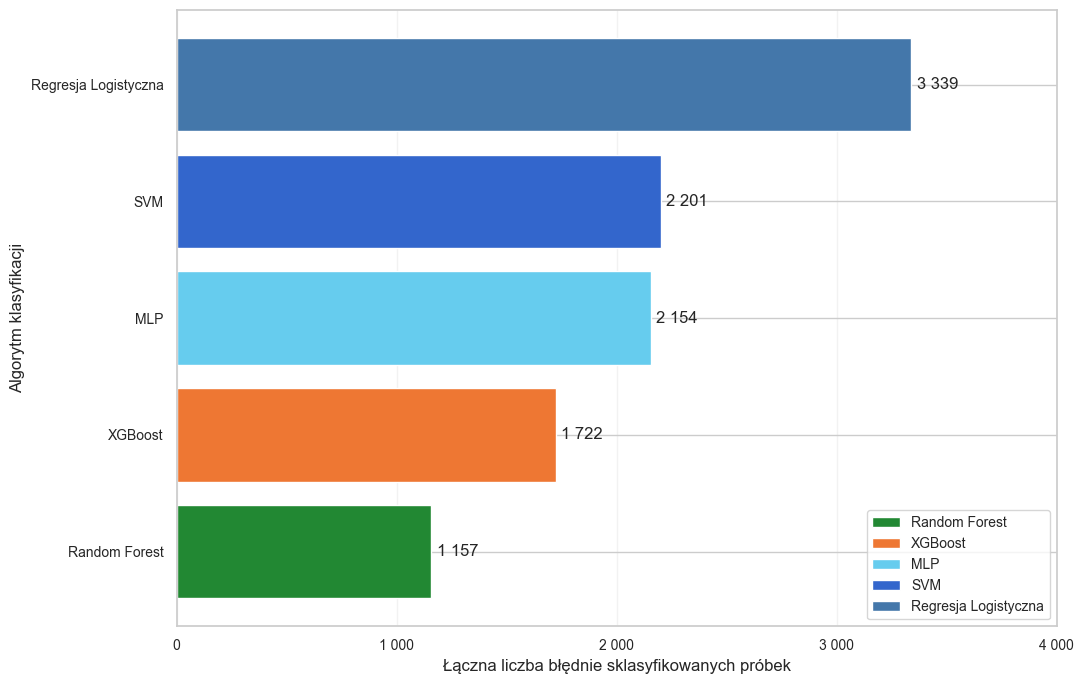

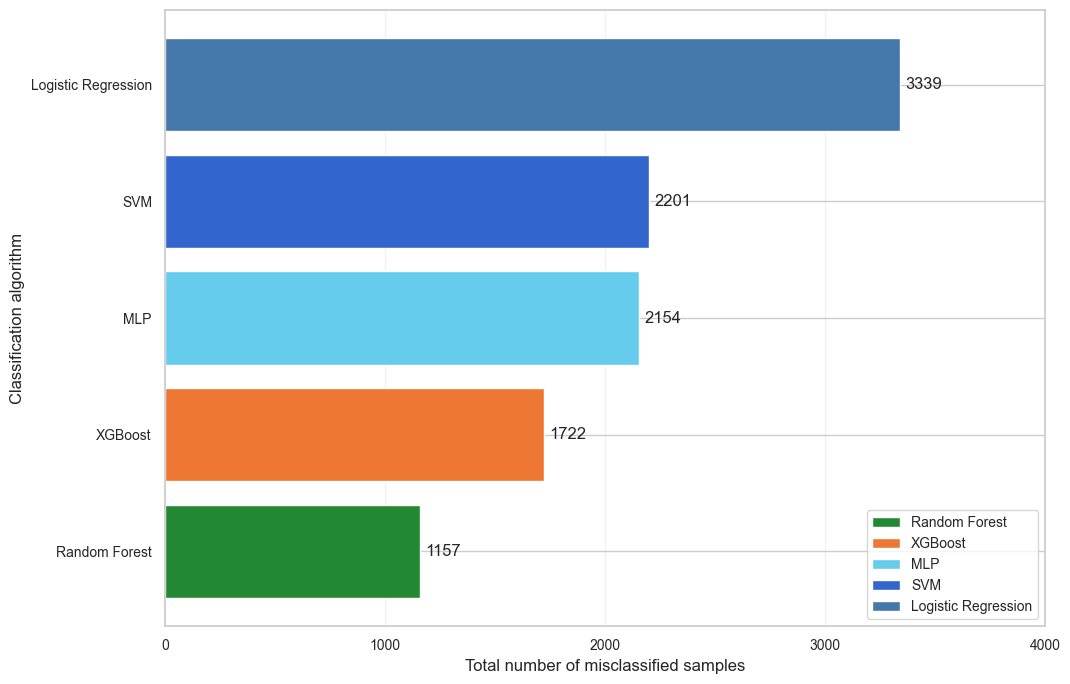

Wariant danych: Pełny zbiór | Faza: 5 | Średnie miary jakości


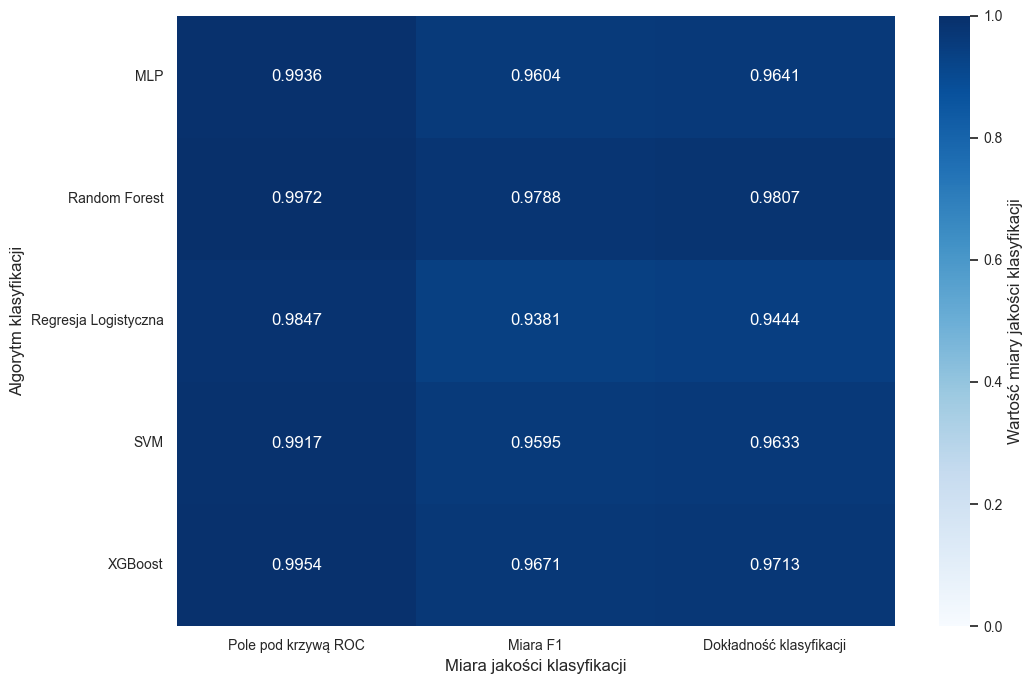

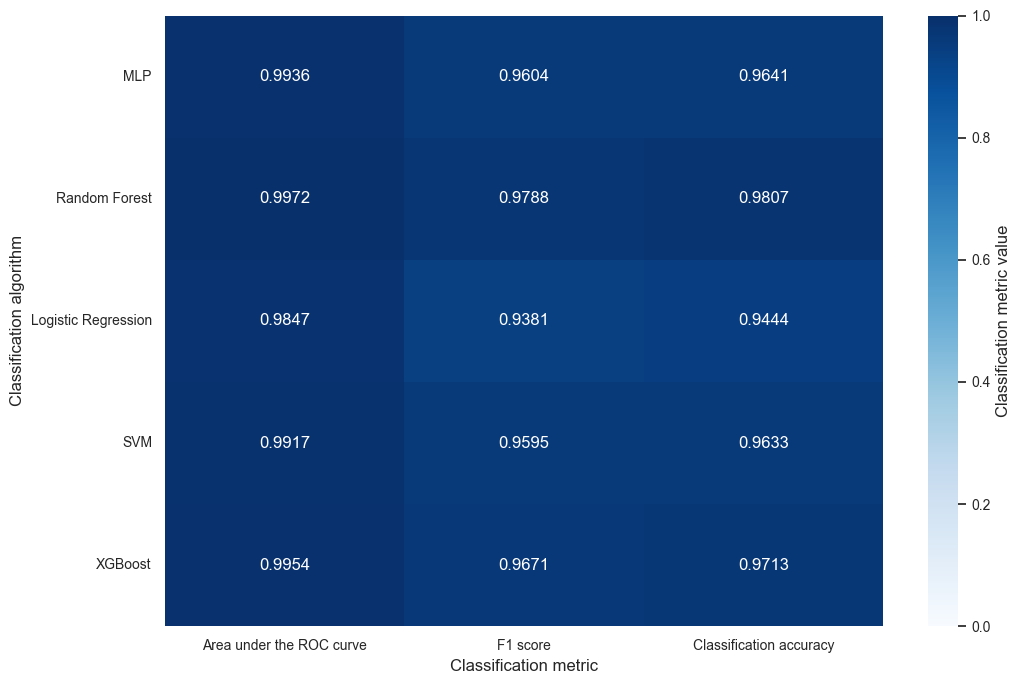

Wariant danych: Zoptymalizowany zbiór | Faza: 5 | Ranking według pola pod krzywą ROC


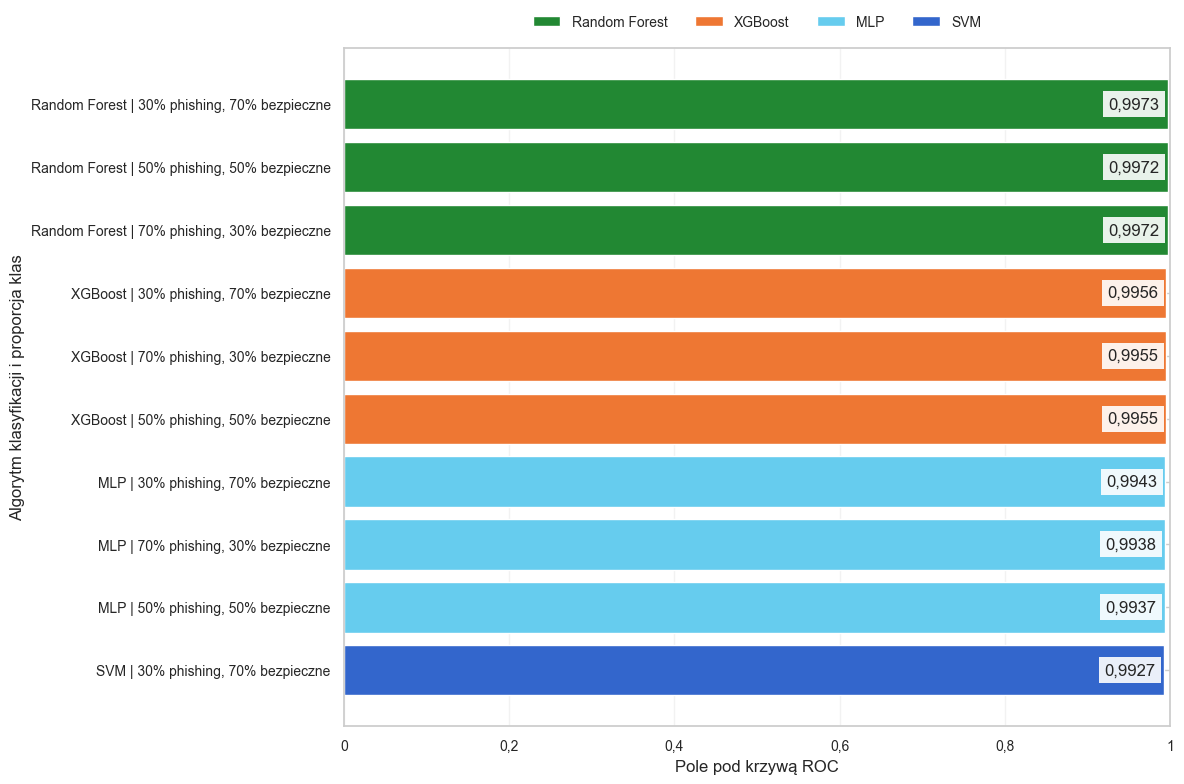

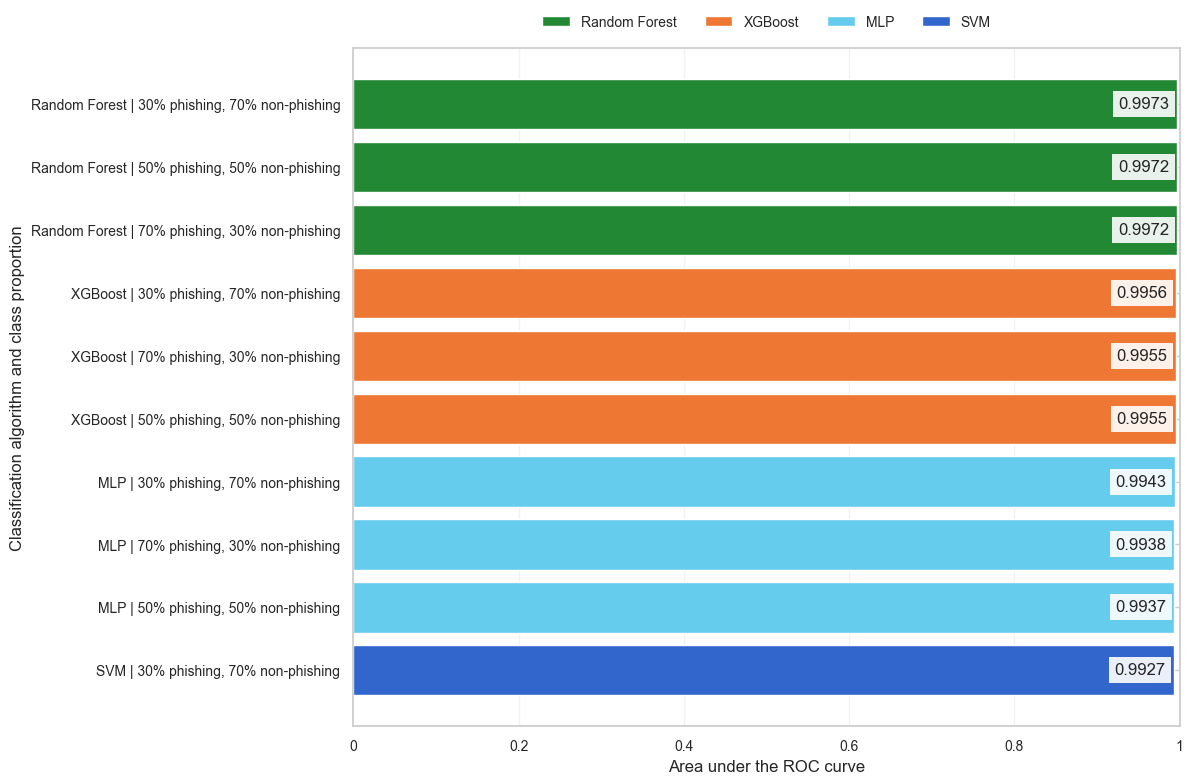

Wariant danych: Zoptymalizowany zbiór | Faza: 5 | Łączna liczba błędnych klasyfikacji


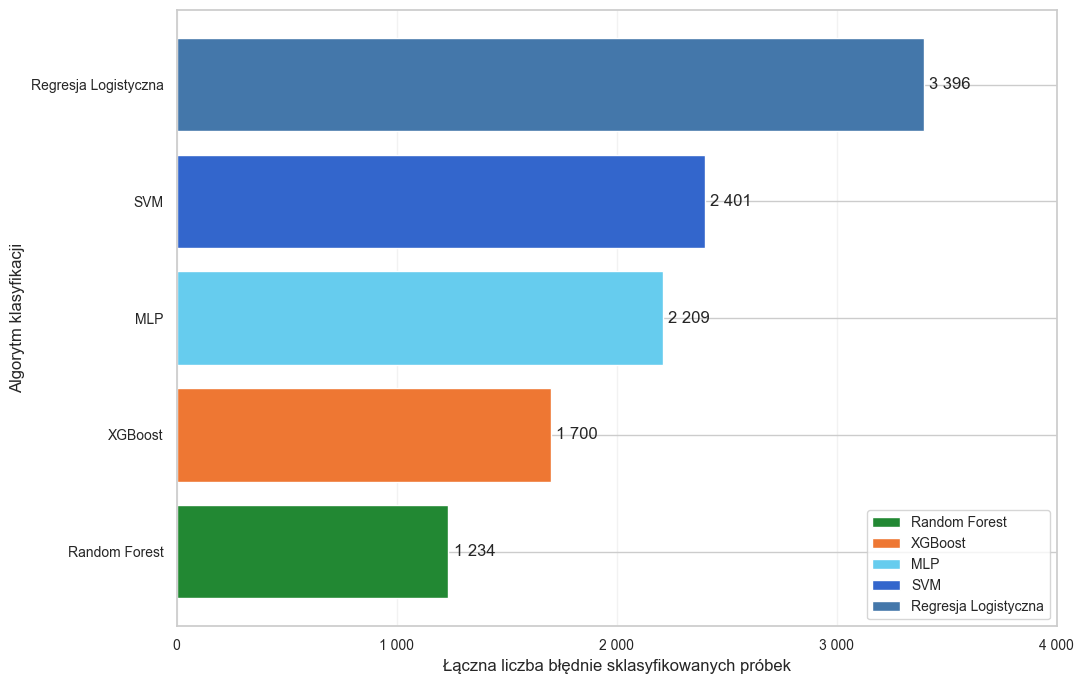

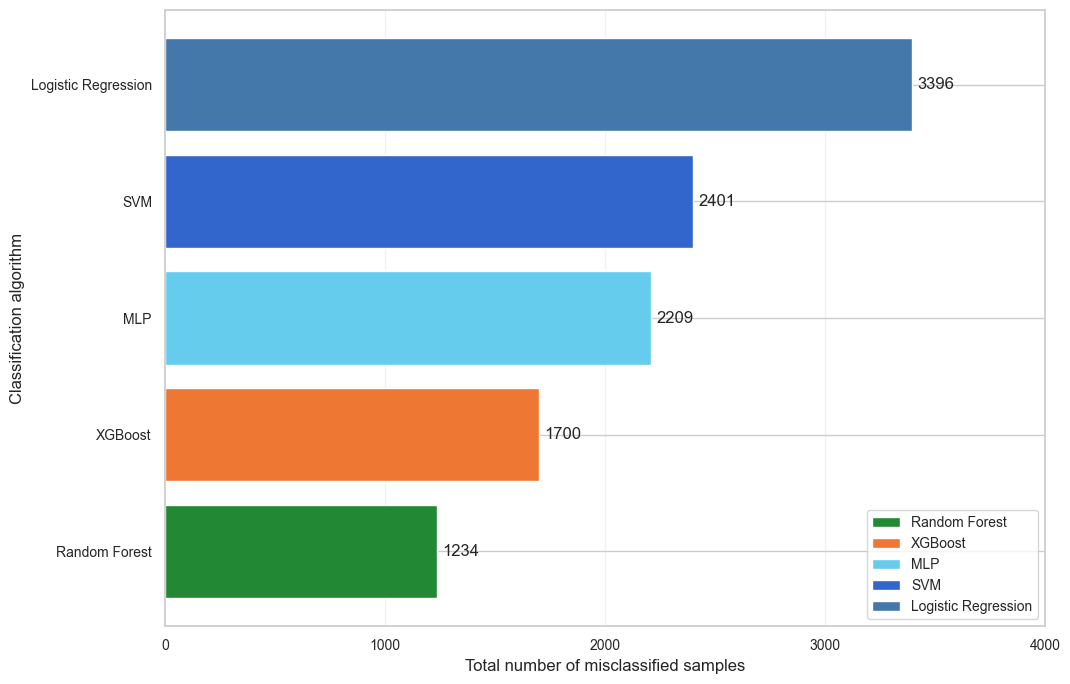

Wariant danych: Zoptymalizowany zbiór | Faza: 5 | Średnie miary jakości


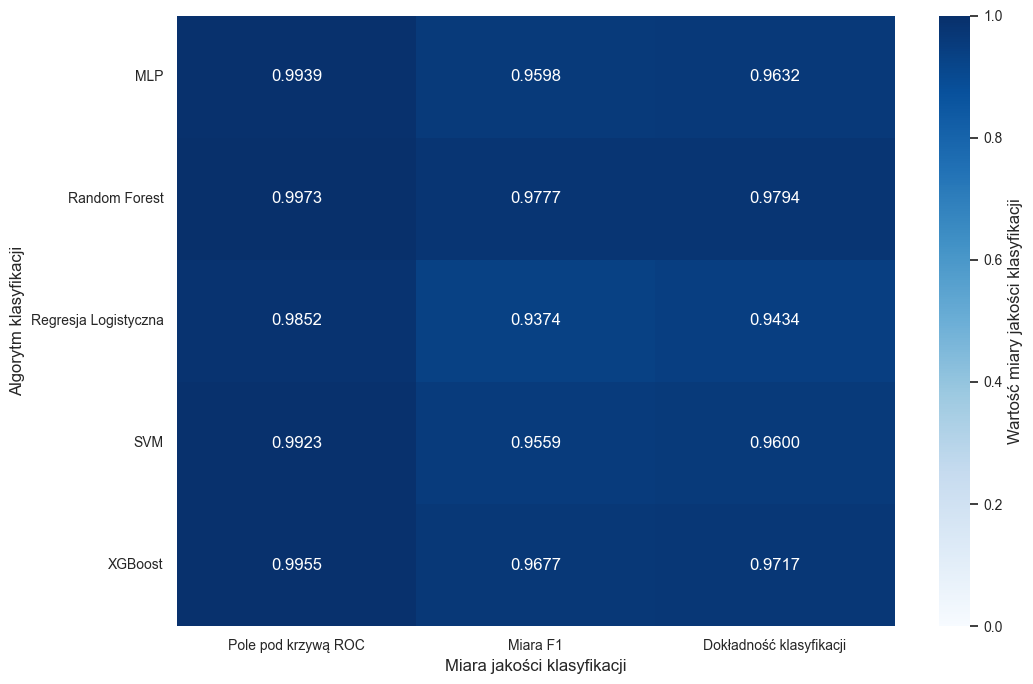

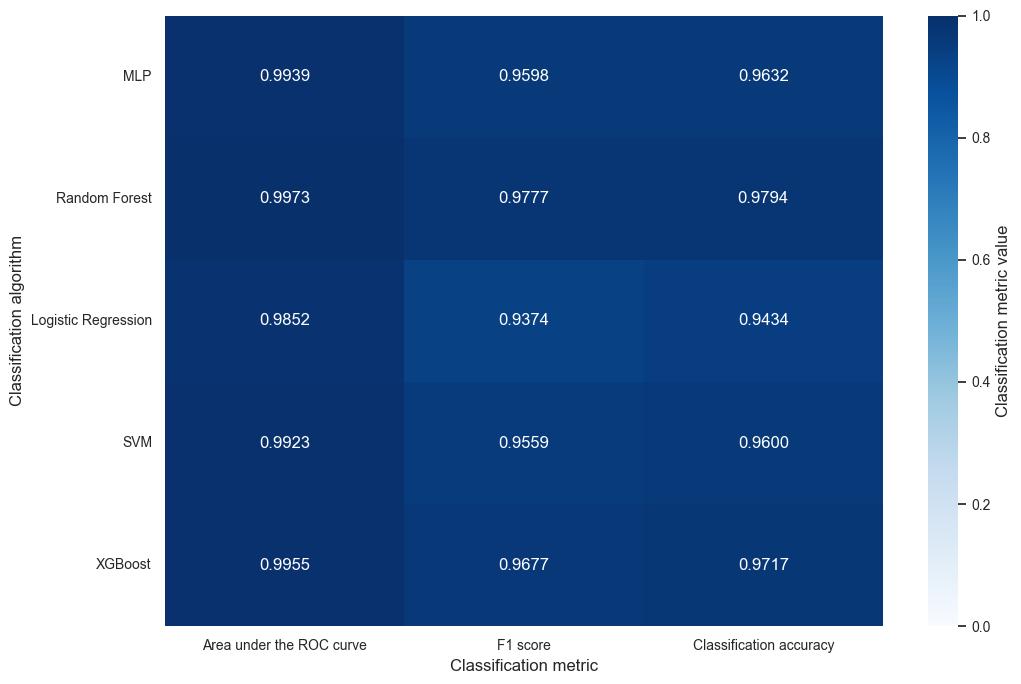

Zapisano statystyki dla wszystkich faz. W notebooku pokazano szczegółowo wyłącznie fazę 5.


In [26]:
from utils.phase_testing_plots import (
    plot_count_ranking,
    plot_metric_heatmap,
    plot_probability_ranking,
)

phase_mapping = {
    'Faza 1: Mini Test': 1, 'Faza 2: 1,000 próbek': 2,
    'Faza 3: 5,000 próbek': 3, 'Faza 4: 10,000 próbek': 4,
    'Faza 5: 20,000 próbek': 5,
}
for phase_name in phase_summary_df['Faza'].unique():
    phase_folder = PLOTS_DIR / f"phase_{phase_mapping[phase_name]}"
    for dataset_type in ['full', 'optimized']:
        data = phase_summary_df[
            (phase_summary_df['Faza'] == phase_name)
            & (phase_summary_df['Zbior'] == dataset_type)
        ]
        if data.empty:
            continue
        show_inline = phase_mapping[phase_name] == 5
        top = data.nlargest(10, 'ROC-AUC').reset_index(drop=True)
        labels = top['Model'] + ' | ' + top['Rozklad']
        if show_inline:
            print(
                f'Wariant danych: {dataset_display_name(dataset_type)} | '
                'Faza: 5 | Ranking według pola pod krzywą ROC'
            )
        figure = plot_probability_ranking(
            labels, top['ROC-AUC'].to_numpy(), dataset_type,
        )
        figure.tight_layout()
        save_dataset_figure(
            figure, phase_folder, dataset_type, 'roc_auc_ranking.png',
            display_in_notebook=show_inline,
        )
        plt.close(figure)

        errors = data.groupby('Model')['Bledne'].sum().sort_values()
        if show_inline:
            print(
                f'Wariant danych: {dataset_display_name(dataset_type)} | '
                'Faza: 5 | Łączna liczba błędnych klasyfikacji'
            )
        figure = plot_count_ranking(
            errors.index.tolist(), errors.to_numpy(), total=True,
        )
        figure.tight_layout()
        save_dataset_figure(
            figure, phase_folder, dataset_type, 'classification_errors.png',
            display_in_notebook=show_inline,
        )
        plt.close(figure)

        metrics = data.groupby('Model')[['ROC-AUC', 'F1', 'Dokladnosc']].mean()
        metrics = metrics.rename(columns={
            'ROC-AUC': 'Pole pod krzywą ROC',
            'F1': 'Miara F1',
            'Dokladnosc': 'Dokładność klasyfikacji',
        })
        if show_inline:
            print(
                f'Wariant danych: {dataset_display_name(dataset_type)} | '
                'Faza: 5 | Średnie miary jakości'
            )
        figure = plot_metric_heatmap(metrics, dataset_type)
        figure.tight_layout()
        save_dataset_figure(
            figure, phase_folder, dataset_type, 'average_quality_metrics.png',
            display_in_notebook=show_inline,
        )
        plt.close(figure)

print(
    'Zapisano statystyki dla wszystkich faz. '
    'W notebooku pokazano szczegółowo wyłącznie fazę 5.'
)

full_summary = phase_summary_df[phase_summary_df['Zbior'] == 'full'].groupby('Model').agg({
    'ROC-AUC': ['mean', 'std', 'count'], 'F1': ['mean', 'std'],
    'Dokladnosc': ['mean', 'std'], 'Bledne': 'sum',
}).round(4)
opt_summary = phase_summary_df[phase_summary_df['Zbior'] == 'optimized'].groupby('Model').agg({
    'ROC-AUC': ['mean', 'std', 'count'], 'F1': ['mean', 'std'],
    'Dokladnosc': ['mean', 'std'], 'Bledne': 'sum',
}).round(4)
improvement_rows = []
for model in set(full_summary.index) & set(opt_summary.index):
    full_roc = full_summary.loc[model, ('ROC-AUC', 'mean')]
    opt_roc = opt_summary.loc[model, ('ROC-AUC', 'mean')]
    full_f1 = full_summary.loc[model, ('F1', 'mean')]
    opt_f1 = opt_summary.loc[model, ('F1', 'mean')]
    improvement_rows.append({
        'Model': model, 'ROC-AUC Poprawa (%)': (opt_roc-full_roc)/full_roc*100,
        'F1 Poprawa (%)': (opt_f1-full_f1)/full_f1*100,
        'Pelny ROC-AUC': full_roc, 'Zoptym ROC-AUC': opt_roc,
    })
pd.DataFrame(improvement_rows).to_csv(
    RESULTS_DIR / 'summary' / 'dataset_improvement_analysis.csv', index=False
)


## 13. Podsumowanie testowania fazowego


In [27]:
print('='*100)
print('PODSUMOWANIE KONCOWE - TESTOWANIE FAZOWE MODELI')
print('='*100)

total_tests = len(phase_summary_df)
total_phases = len(phase_results)
total_plots = len(list(PLOTS_DIR.glob('**/*.png')))
total_csvs = len(list(RESULTS_DIR.glob('**/*.csv')))

print(f'\nPrzeprowadzono {total_phases} faz testowania')
print(f'Laczna liczba testow: {total_tests}')
print(f'Liczba modeli: {len(loaded_models)}')
print(f'Warianty zbiorow danych: {len(test_datasets)}')
print(f'Wygenerowano wizualizacji: {total_plots}')
print(f'Wygenerowano plikow CSV: {total_csvs}')

print('='*100)
print('TOP 3 MODELE (OGOLNIE - WSZYSTKIE FAZY I ROZKLADY)')
print('='*100)

model_avg_scores = ranking_df.groupby('Model').agg({
    'Wynik rankingowy': 'mean',
    'ROC-AUC': 'mean',
    'F1': 'mean',
    'Dokładność': 'mean'
}).reset_index()

model_avg_scores = model_avg_scores.sort_values('Wynik rankingowy', ascending=False)

for i, (idx, row) in enumerate(model_avg_scores.head(3).iterrows()):
    medal = 'GOLD' if i == 0 else 'SILVER' if i == 1 else 'BRONZE'
    print(f"{medal} {row['Model']}")
    print(f"   Średni wynik rankingowy: {row['Wynik rankingowy']:.4f}")
    print(f"   Średnie ROC-AUC: {row['ROC-AUC']:.4f} | Średnie F1: {row['F1']:.4f} | Średnia dokładność: {row['Dokładność']:.4f}")
    print()

print('='*100)
print('TOP 3 MODELE DLA KAZDEJ FAZY (ROZKLAD 50/50)')
print('='*100)
for phase_name in phase_summary_df['Faza'].unique():
    phase_50_50 = ranking_df[
        (ranking_df['Faza'] == phase_name) &
        (ranking_df['Rozkład'] == '50% phishing, 50% bezpieczne')
    ].head(3)

    print(f'\n{phase_name}:')
    for idx, row in enumerate(phase_50_50.iterrows(), 1):
        row_data = row[1]
        print(f"  {idx}. {row_data['Model']} ({row_data['Zbiór']}) - "
              f"Wynik: {row_data['Wynik rankingowy']:.4f} | ROC-AUC: {row_data['ROC-AUC']:.4f} | "
              f"F1: {row_data['F1']:.4f}")

print('\n' + '='*100)
print('PODSUMOWANIE WEDLUG ROZMIARU ZBIORU')
print('='*100)
size_summary = phase_summary_df.groupby('Faza').agg({
    'Dokladnosc': ['mean', 'std', 'min', 'max'],
    'F1': ['mean', 'std', 'min', 'max'],
    'ROC-AUC': ['mean', 'std', 'min', 'max'],
    'Bledne': 'sum'
}).round(4)
print(size_summary)

print('\n' + '='*100)
print('PODSUMOWANIE WEDLUG ROZKLADU KLAS')
print('='*100)
dist_summary = phase_summary_df.groupby('Rozklad').agg({
    'Dokladnosc': ['mean', 'std'],
    'F1': ['mean', 'std'],
    'ROC-AUC': ['mean', 'std'],
    'Bledne': 'sum'
}).round(4)
print(dist_summary)

print('\n' + '='*100)
print('PODSUMOWANIE WEDLUG MODELU')
print('='*100)
model_summary = phase_summary_df.groupby('Model').agg({
    'Dokladnosc': ['mean', 'std'],
    'F1': ['mean', 'std'],
    'ROC-AUC': ['mean', 'std'],
    'Bledne': 'sum'
}).round(4)
model_summary = model_summary.sort_values(('ROC-AUC', 'mean'), ascending=False)
print(model_summary)

print('\n' + '='*100)
print('STRUKTURA KATALOGOW Z WYNIKAMI')
print('='*100)
print(f'\nFolder {RESULTS_DIR}/')
print(f'  ├── summary/')
print(f'  │   ├── all_phases_results.csv')
print(f'  │   ├── complete_ranking.csv')
print(f'  │   ├── model_summary.csv')
print(f'  │   └── all_phases_misclassifications.csv')
for i in range(1, 6):
    phase_csv_count = len(list((RESULTS_DIR / f'phase_{i}').glob('*.csv')))
    print(f'  ├── phase_{i}/ ({phase_csv_count} plikow CSV)')
    print(f'  │   ├── phase_{i}_detailed_results.csv')
    print(f'  │   ├── phase_{i}_ranking.csv')
    print(f'  │   └── phase_{i}_misclassifications.csv')

print(f'\nFolder {PLOTS_DIR}/')
print(f'  ├── summary/')
print(f'  │   ├── size_impact_all_phases.png')
print(f'  │   └── distribution_impact_phase5.png')
for i in range(1, 6):
    phase_plot_count = len(list((PLOTS_DIR / f'phase_{i}').glob('*.png')))
    print(f'  ├── phase_{i}/ ({phase_plot_count} wizualizacji)')
    print(f'  │   ├── confusion_matrices_*.png (3 pliki)')
    print(f'  │   ├── metrics_comparison_*.png (3 pliki)')
    print(f'  │   ├── misclassification_dist_*.png (3 pliki)')
    print(f'  │   └── phase_{i}_statistics.png')

print('\n' + '='*100)
print('PODSUMOWANIE WYGENEROWANYCH PLIKOW')
print('='*100)
print(f'  Pliki CSV: {total_csvs}')
print(f'     • Wyniki fazowe: 5 plikow')
print(f'     • Rankingi fazowe: 5 plikow')
print(f'     • Bledne klasyfikacje fazowe: 5 plikow')
print(f'     • Podsumowania: 4 pliki w folderze summary')
print(f'\n  Wizualizacje: {total_plots}')
print(f'     • Macierze pomylek: ~15 plikow (3 na faze)')
print(f'     • Porownania metryk: ~15 plikow (3 na faze)')
print(f'     • Rozklady bledow: ~15 plikow (3 na faze)')
print(f'     • Statystyki fazowe: 5 plikow (1 na faze)')
print(f'     • Podsumowania: 2 pliki w folderze summary')

print('\nTestowanie fazowe zakonczone pomyslnie!')
print('Wszystkie wyniki zorganizowane w podfolderach wedlug faz')
print('='*100)

PODSUMOWANIE KONCOWE - TESTOWANIE FAZOWE MODELI

Przeprowadzono 5 faz testowania
Laczna liczba testow: 130
Liczba modeli: 5
Warianty zbiorow danych: 2
Wygenerowano wizualizacji: 208
Wygenerowano plikow CSV: 23
TOP 3 MODELE (OGOLNIE - WSZYSTKIE FAZY I ROZKLADY)
GOLD Random Forest
   Średni wynik rankingowy: 0.9864
   Średnie ROC-AUC: 0.9978 | Średnie F1: 0.9807 | Średnia dokładność: 0.9822

SILVER XGBoost
   Średni wynik rankingowy: 0.9772
   Średnie ROC-AUC: 0.9956 | Średnie F1: 0.9690 | Średnia dokładność: 0.9730

BRONZE Regresja Logistyczna
   Średni wynik rankingowy: 0.9574
   Średnie ROC-AUC: 0.9857 | Średnie F1: 0.9439 | Średnia dokładność: 0.9496

TOP 3 MODELE DLA KAZDEJ FAZY (ROZKLAD 50/50)

Faza 1: Mini Test:
  1. Regresja Logistyczna (Pełny zbiór (111 cech)) - Wynik: 1.0000 | ROC-AUC: 1.0000 | F1: 1.0000
  2. Random Forest (Pełny zbiór (111 cech)) - Wynik: 1.0000 | ROC-AUC: 1.0000 | F1: 1.0000
  3. Random Forest (Zoptymalizowany zbiór (74 cech)) - Wynik: 1.0000 | ROC-AUC: 1.00

## 14. Końcowe porównanie algorytmów


In [28]:
from utils.final_model_comparison import (
    generate_final_model_comparisons,
    missing_final_model_results,
)

comparison_root = RESULTS_DIR.parent
comparison_input = comparison_root / 'model_comparisons'
missing_comparisons = missing_final_model_results(comparison_input)
if missing_comparisons:
    missing_names = ', '.join(path.name for path in missing_comparisons)
    print(f'Pominięto końcowe porównanie modeli. Brak plików: {missing_names}')
    print('Po uzupełnieniu wyników uruchom build_final_model_comparisons.py.')
else:
    final_model_results, final_comparison_paths = generate_final_model_comparisons(
        comparison_input, comparison_root / 'final_model_comparison',
        display_in_notebook=False,
    )
    display(final_model_results)
    print('\nZapisane końcowe wykresy porównawcze:')
    for path in final_comparison_paths:
        print(f'  • {path}')


,Algorytm klasyfikacji,Zbiór danych,Dokładność,Precyzja,Czułość,Miara F1,AUC-ROC,Współczynnik błędu klasyfikacji,Czas uczenia (s),Liczba cech,Średnie CPU [%],Średni RAM [GB]
0,Regresja logistyczna,Pełny zbiór,0.930826,0.918662,0.945342,0.931811,0.979514,0.069174,1.678303,111,16.623933,0.723194
1,Regresja logistyczna,Zoptymalizowany zbiór,0.929502,0.917317,0.944089,0.930511,0.977993,0.070498,1.235167,74,17.623058,0.770495
2,Random Forest,Pełny zbiór,0.969655,0.964799,0.974874,0.969810,0.995169,0.030345,1.436483,111,86.324536,0.390220
3,Random Forest,Zoptymalizowany zbiór,0.968686,0.965478,0.972127,0.968791,0.994599,0.031314,1.349227,74,84.216486,0.354439
4,XGBoost,Pełny zbiór,0.971450,0.970526,0.972426,0.971475,0.995303,0.028550,0.756016,111,33.039948,0.283506
5,XGBoost,Zoptymalizowany zbiór,0.969752,0.969057,0.970487,0.969771,0.994927,0.030248,0.600828,74,34.176346,0.261171
6,SVM,Pełny zbiór,0.958561,0.955880,0.961495,0.958679,0.989382,0.041439,497.775597,111,9.087456,0.504572
7,SVM,Zoptymalizowany zbiór,0.954341,0.953667,0.955075,0.954370,0.988945,0.045659,308.520435,74,9.088122,0.497035
8,MLP,Pełny zbiór,0.959295,0.960569,0.957905,0.959235,0.992868,0.040705,12.496666,111,13.115292,0.650765
9,MLP,Zoptymalizowany zbiór,0.959013,0.962651,0.955075,0.958848,0.991793,0.040987,18.430600,74,13.907022,0.639915



Zapisane końcowe wykresy porównawcze:
  • /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/final_model_comparison/plots/pl/quality_full.png
  • /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/final_model_comparison/plots/pl/errors_full.png
  • /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/final_model_comparison/plots/pl/quality_optimized.png
  • /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/final_model_comparison/plots/pl/errors_optimized.png
  • /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/final_model_comparison/plots/pl/training_time.png
  • /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/final_model_comparison/plots/pl/average_cpu.png
  • /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/final_model_comparison/plots/